# Customer Churn Intelligence & Retention Analytics
## Phase 2: Data Audit (raw data, read-only)

**Rule:** In this phase we only *look*. We do not fix, drop or convert anything. Every finding goes in the *My finding* cell under each step. Phase 3 will turn your findings into cleaning decisions (Problem → Evidence → Decision → Result).

Work top to bottom. Cells marked **YOUR TURN** are left for you to write.

In [ ]:
import pandas as pd
pd.set_option('display.max_columns', None)

RAW = '../data/raw/customer_churn_raw.csv'

# Read EVERYTHING as text first. Why? If pandas guesses types on load, it can silently hide problems
# (e.g. a number column quietly becoming text, or blanks becoming NaN). We want to see the file as it is.
df_text = pd.read_csv(RAW, dtype=str, keep_default_na=False)

# Normal load, which is what you'd get by default. We'll compare the two later.
df = pd.read_csv(RAW)

### 1. Shape
**Detects:** Did the file load completely? Does the row count match what you expect (7,043 customers, 33 columns)? A wrong shape usually means a bad delimiter or truncated file.

In [ ]:
df.shape

### 2. Column names
**Detects:** Spaces, mixed case, odd characters, or columns that are redundant. Messy names make SQL and Power BI harder later.

In [ ]:
# YOUR TURN: list the column names.


**My finding:** (Which names would be annoying in SQL? Which columns look pointless for analysis?)

### 3. Data types
**Detects:** Numbers stored as text, categories stored as numbers, dates stored as strings. Compare `df.dtypes` with what each column *should* be.

In [ ]:
df.dtypes

**My finding:** (Which column has a type that doesn't match its meaning? Look for `object`/`str` on something numeric.)

### 4. First and last rows
**Detects:** Header problems, footer/total rows, sorting patterns, and a feel for what a normal row looks like.

In [ ]:
# YOUR TURN: show the first 5 and last 5 rows. Tip: .T makes 33 columns readable.


### 5. Missing values
**Detects:** Blank cells. But be careful: pandas only counts *true* empty cells as missing. Blank strings or placeholders like `' '`, `'N/A'`, `'?'` are not counted unless you look for them.

In [ ]:
# Step A: standard null count
df.isna().sum()[lambda s: s > 0]

In [ ]:
# YOUR TURN, Step B: use df_text to find cells that are empty or only whitespace, per column.
# Hint: df_text[col].str.strip() == ''


**My finding:** (Which columns have nulls? Is each one a real problem or expected? Does Step B reveal anything Step A missed?)

### 6. Duplicates
**Detects:** The same customer appearing twice, which inflates counts and churn rate. Check full-row duplicates AND duplicates on the ID column alone, because they can differ.

In [ ]:
# YOUR TURN: count full-row duplicates, then duplicates on CustomerID only.


### 7. Unique values and cardinality
**Detects:** Columns with one value (useless), columns with all-unique values (IDs), and categories that should be the same but are spelled differently (`Yes`/`yes`/`Y`).

In [ ]:
df.nunique().sort_values()

In [ ]:
# YOUR TURN: for every column with fewer than 10 unique values, print the column name and its value_counts().


**My finding:** (Which columns have a single value? Any category that looks odd, like a value that overlaps in meaning with another? Read the service columns carefully.)

### 8. Numerical summary statistics
**Detects:** Impossible values (negative tenure, zero charges), extreme outliers, and skew. Compare mean vs median and look at min/max.

In [ ]:
df.describe().T

**My finding:** (Do min and max make business sense for tenure and monthly charges?)

### 9. Suspicious values: logic checks
**Detects:** Values that are individually valid but contradict each other. Example: a customer with tenure 0 should not have large total charges.

In [ ]:
# Convert Total Charges to numbers WITHOUT changing df: errors='coerce' turns unparseable text into NaN.
tc = pd.to_numeric(df_text['Total Charges'], errors='coerce')

# YOUR TURN:
# 1) How many Total Charges values failed to convert?
# 2) What is the Tenure Months of those rows?
# 3) Does Total Charges roughly equal Tenure Months x Monthly Charges for the other rows? Check a few.


### 10. Inconsistent formatting
**Detects:** Leading/trailing spaces, mixed capitalisation, and inconsistent formats that break grouping.

In [ ]:
# YOUR TURN: for each text column in df_text, count values where value != value.strip().


### 11. Target variable check
**Detects:** Whether the churn columns agree with each other and how imbalanced the classes are.

In [ ]:
# YOUR TURN: value_counts of 'Churn Label' and 'Churn Value'. Do they match row for row?
# Then: is 'Churn Reason' filled only for churned customers?


## Audit summary (fill this in before Phase 3)

| # | Column | Problem | Evidence | Severity (low/med/high) |
|---|--------|---------|----------|------------------------|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

---
# Phase 3: Data Cleaning
**Principle:** the raw file is never modified. We clean a copy (`clean`) and write the result to `data/clean/`.
Every decision below follows **Problem → Evidence → Decision → Result**, and every number is computed in the cell, not typed by hand.

In [ ]:
import numpy as np
clean = df_text.copy()          # work on a copy of the raw text version; raw CSV on disk is untouched
rows_before, cols_before = clean.shape
print(rows_before, cols_before)

### 3.1 Duplicates
- **Problem:** Duplicate customers would inflate customer counts and distort churn rate.
- **Evidence:** run the cell below (full-row duplicates and duplicate `CustomerID`).
- **Decision:** none found, so nothing is dropped. We still add an `assert` so that if the data is ever refreshed with duplicates, the pipeline fails loudly instead of silently double-counting.
- **Result:** 7,043 unique customers.

In [ ]:
print('full-row duplicates:', clean.duplicated().sum())
print('duplicate CustomerID:', clean['CustomerID'].duplicated().sum())
assert clean['CustomerID'].is_unique

### 3.2 Column names
- **Problem:** Names contain spaces and mixed case (`Monthly Charges`, `Churn Label`). In SQL these need quoting, and in Power BI/DAX they are error-prone.
- **Evidence:** `[c for c in df.columns if ' ' in c]`
- **Decision:** convert to `snake_case` (`monthly_charges`). This changes labels only, not values.
- **Result:** all column names are lowercase with underscores.

In [ ]:
print('columns with spaces before:', sum(' ' in c for c in clean.columns))
clean.columns = (clean.columns.str.strip().str.lower()
                 .str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_'))
clean = clean.rename(columns={'customerid': 'customer_id'})   # CustomerID is one word in the source, so give it a readable name
print('columns with spaces after :', sum(' ' in c for c in clean.columns))
print(list(clean.columns))

### 3.3 Whitespace
- **Problem:** Stray spaces make `'Yes'` and `'Yes '` count as different categories.
- **Evidence:** in the audit, the only column with leading/trailing whitespace is `Total Charges` (the 11 cells that are just a space). Check below.
- **Decision:** strip whitespace on all text columns. This is a no-op on every column except `total_charges`, but it is cheap and makes the pipeline safe on future data.
- **Result:** zero values with leading/trailing whitespace.

In [ ]:
obj_cols = clean.columns
before = {c: (clean[c] != clean[c].str.strip()).sum() for c in obj_cols}
print({c: n for c, n in before.items() if n})
for c in obj_cols:
    clean[c] = clean[c].str.strip()
print('remaining:', sum((clean[c] != clean[c].str.strip()).sum() for c in obj_cols))

### 3.4 `total_charges` stored as text, with 11 blank values
- **Problem:** `Total Charges` is text, so it cannot be summed or averaged. The cause is 11 cells containing only a space.
- **Evidence:** converting with `errors='coerce'` fails for exactly those 11 rows. All 11 have `tenure_months = 0` and `churn_value = 0`: they are brand-new customers who have not been billed yet. For the other rows, `total_charges / (tenure_months * monthly_charges)` has median 1.00, so the column behaves as expected.
- **Decision:** convert to a number and set the 11 blanks to **0**. Not dropping: they are real customers and removing them would change the customer count. Not mean/median imputation: that would invent revenue that was never billed. 0 is the factual value (nothing billed yet).
- **Result:** `total_charges` is `float64` with no nulls.

In [ ]:
tc = pd.to_numeric(clean['total_charges'], errors='coerce')
bad = tc.isna()
print('failed to convert:', bad.sum())
print('their tenure values   :', clean.loc[bad, 'tenure_months'].unique())
print('their churn values    :', clean.loc[bad, 'churn_value'].unique())
ratio = tc[~bad] / (clean.loc[~bad, 'tenure_months'].astype(int) * clean.loc[~bad, 'monthly_charges'].astype(float))
print('median total/(tenure*monthly):', round(ratio.median(), 3))

clean['total_charges'] = tc.fillna(0.0)
print(clean['total_charges'].dtype, clean['total_charges'].isna().sum())

### 3.5 Other data types
- **Problem:** Because we loaded everything as text, numeric columns must be converted back. `zip_code` should be an identifier (text), not a number: you never average zip codes.
- **Evidence:** `df.dtypes` in the audit shows pandas guessed `Zip Code` as an integer.
- **Decision:** numeric columns to numbers (`tenure_months`, `monthly_charges`, `latitude`, `longitude`, `churn_value`, `churn_score`, `cltv`); `zip_code` stays text.
- **Result:** each column's type matches its meaning (checked in the final summary).

In [ ]:
num_int   = ['tenure_months', 'churn_value', 'churn_score', 'cltv']
num_float = ['monthly_charges', 'latitude', 'longitude']
clean[num_int]   = clean[num_int].astype(int)
clean[num_float] = clean[num_float].astype(float)
clean.dtypes

### 3.6 Redundant "No internet service" / "No phone service" categories
- **Problem:** Seven columns mix two meanings: `No` (has the service type but declined the add-on) and `No internet service` / `No phone service` (cannot have the add-on at all).
- **Evidence:** crosstabs show `No internet service` appears exactly 1,526 times in every internet add-on column, always where `internet_service = 'No'`. `No phone service` appears 682 times in `multiple_lines`, exactly where `phone_service = 'No'`. The information is already stored in `internet_service` and `phone_service`.
- **Decision:** recode both to `No` in the seven add-on columns. The original information is not lost (it lives in the parent columns), and it makes every add-on a clean Yes/No, so service counts and encodings in later phases are correct. Caveat for later: when analysing add-ons such as Tech Support, filter to customers who have internet, otherwise the `No` group mixes people who declined with people who couldn't have it.
- **Result:** those seven columns contain only `Yes` and `No`.

In [ ]:
addons = ['multiple_lines', 'online_security', 'online_backup', 'device_protection',
          'tech_support', 'streaming_tv', 'streaming_movies']
print(pd.crosstab(clean['internet_service'], clean['online_security']), '\n')
clean[addons] = clean[addons].replace({'No internet service': 'No', 'No phone service': 'No'})
for c in addons:
    print(c, clean[c].unique())

### 3.7 Columns that add no analytical value
- **Problem:** Constant or duplicated columns clutter the dataset and add noise to models.
- **Evidence:** `count`, `country`, `state` each have exactly one value across all rows. `lat_long` is the text concatenation of `latitude` and `longitude` (100% match in the audit).
- **Decision:** drop those four. Keep `city`, `zip_code`, `latitude`, `longitude` in case we want a geographic view.
- **Result:** four fewer columns; no information lost.

In [ ]:
drop_cols = ['count', 'country', 'state', 'lat_long']
for c in ['count', 'country', 'state']:
    assert clean[c].nunique() == 1, c
ll = clean['lat_long'].str.split(', ', expand=True).astype(float)
assert np.allclose(ll[0], clean['latitude']) and np.allclose(ll[1], clean['longitude'])   # lat_long is fully redundant
clean = clean.drop(columns=drop_cols)
clean.shape

### 3.8 Missing values in `churn_reason`
- **Problem:** `churn_reason` is empty for 5,174 customers.
- **Evidence:** it is empty for exactly the customers with `churn_value = 0`, and filled for all 1,869 churned customers. It is not missing data; a customer who stayed has no reason for leaving.
- **Decision:** leave it empty (`NaN`/NULL in SQL). Do **not** fill with "Unknown" or "Retained", which would invent a category. Warning for Phase 8: this column is only known *after* churn, so it must be excluded from any prediction model (data leakage).
- **Result:** nulls remain only in `churn_reason`, and only where expected.

In [ ]:
clean['churn_reason'] = clean['churn_reason'].replace('', np.nan)
print(pd.crosstab(clean['churn_value'], clean['churn_reason'].isna(), rownames=['churn'], colnames=['reason is null']))
assert clean.loc[clean['churn_value'] == 1, 'churn_reason'].notna().all()
assert clean.loc[clean['churn_value'] == 0, 'churn_reason'].isna().all()

### 3.9 Impossible values and outliers
- **Problem:** Impossible values (negative tenure, zero or negative charges, out-of-range scores) and extreme outliers would distort averages.
- **Evidence:** the checks below. Tenure is 0-72 months, monthly charges 18.25-118.75, churn score 5-100, CLTV 2,003-6,500, and the two churn columns agree on every row.
- **Decision:** no rows removed. Monthly charges and tenure are bounded business quantities with no values outside plausible plan prices and a 6-year customer life. 0-tenure customers are legitimate new customers (see 3.4). Removing "outliers" from a bounded, valid range would throw away real high-paying customers, who are exactly the ones we care about for revenue at risk.
- **Result:** assertions pass; 7,043 rows retained.

In [ ]:
assert clean['tenure_months'].between(0, 72).all()
assert (clean['monthly_charges'] > 0).all()
assert (clean['total_charges'] >= 0).all()
assert clean['churn_score'].between(0, 100).all()
assert (clean['cltv'] > 0).all()
assert set(clean['churn_value'].unique()) == {0, 1}
assert (clean['churn_label'].eq('Yes') == clean['churn_value'].eq(1)).all()
assert clean['zip_code'].str.len().eq(5).all()
print('all validity checks passed')
clean[['tenure_months', 'monthly_charges', 'total_charges']].describe().T

### 3.10 Cleaning summary and export
Before and after, then export to `data/clean/customer_churn_clean.csv`. The raw file is not touched.

In [ ]:
print(f'rows : {rows_before} -> {len(clean)}')
print(f'cols : {cols_before} -> {clean.shape[1]}')
print('nulls:', clean.isna().sum()[lambda s: s > 0].to_dict())
clean.dtypes

In [ ]:
OUT = '../data/clean/customer_churn_clean.csv'
clean.to_csv(OUT, index=False)
print('saved', OUT)

### 3.11 Verify the clean file loads independently
We re-read the exported file from disk, with no reference to the variables above, and check it has the structure we promised. This proves the CSV is self-sufficient for SQL and Power BI.

In [ ]:
check = pd.read_csv('../data/clean/customer_churn_clean.csv', dtype={'zip_code': str})
assert check.shape == (7043, 29), check.shape
assert check['customer_id'].is_unique
assert check['total_charges'].notna().all()
assert check['churn_value'].isin([0, 1]).all()
assert set(check['internet_service']) == {'DSL', 'Fiber optic', 'No'}
assert all(set(check[c]) == {'Yes', 'No'} for c in addons)
print('clean file OK:', check.shape)
print('churn rate:', round(check['churn_value'].mean() * 100, 2), '%')
check.head()

---
# Phase 4: SQL (runs in SQLite, no server needed)
The queries live in `../sql/`. This section loads the clean CSV into an in-memory SQLite database so you can run them here. You can also open the CSV in *DB Browser for SQLite* (File > Import > Table from CSV, name the table `customers`) and paste queries there.

Practice: don't just run the files. Cover the *Result* and *Business interpretation* comments, predict the result, then compare.

In [ ]:
import sqlite3, re
con = sqlite3.connect(':memory:')
pd.read_csv('../data/clean/customer_churn_clean.csv', dtype={'zip_code': str}).to_sql('customers', con, index=False)

def run_sql_file(path):
    """Run every statement in a .sql file; show the result of each SELECT/WITH."""
    code = re.sub(r'--.*', '', open(path).read())
    for stmt in [s.strip() for s in code.split(';') if s.strip()]:
        cur = con.execute(stmt)
        if stmt.upper().startswith(('SELECT', 'WITH')):
            display(pd.DataFrame(cur.fetchall(), columns=[c[0] for c in cur.description]))

run_sql_file('../sql/01_data_validation.sql')

In [ ]:
run_sql_file('../sql/02_customer_analysis.sql')

---
# Phase 5: Exploratory Data Analysis (Python)
Rule for this section: **no chart without a question.** Each one follows **Question → Chart → Observation → Business meaning**. "Business meaning" is what we may *infer*; anything about *cause* is deliberately held back until Phase 6.

Colour code used throughout: **orange = churned / churn rate**, **blue = retained**, grey = comparison group.

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

IMG = Path('../images'); IMG.mkdir(exist_ok=True)
eda = pd.read_csv('../data/clean/customer_churn_clean.csv', dtype={'zip_code': str})

INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
CHURN, STAY, NEUTRAL = '#eb6834', '#2a78d6', '#b9b8b1'
mpl.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRID,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})
overall = eda['churn_value'].mean() * 100          # company-wide churn rate (%)

def rate(df, by):
    """Customers and churn rate (%) per group."""
    g = df.groupby(by)['churn_value'].agg(n='size', pct=lambda s: s.mean() * 100)
    return g

def overall_line(ax, horizontal=True):
    ax.axhline(overall, color=INK2, lw=1, ls='--')
    ax.text(ax.get_xlim()[1], overall, f' company {overall:.1f}%', va='center', ha='left', color=INK2, fontsize=9)

def save(fig, name):
    fig.savefig(IMG / name, dpi=150, bbox_inches='tight')
    plt.show()

print(f'overall churn: {overall:.2f}%')

### 5.1 How big is churn, in customers and in money?
**Question:** Is churn mostly a customer-count problem or a revenue problem?

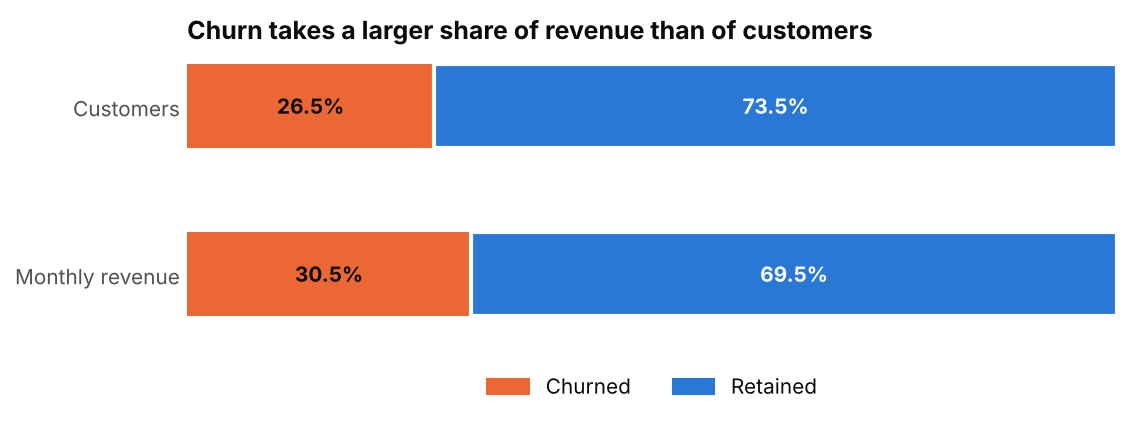

In [ ]:
rev_share = eda.loc[eda.churn_value == 1, 'monthly_charges'].sum() / eda['monthly_charges'].sum() * 100
rows = [('Customers', overall), ('Monthly revenue', rev_share)]

fig, ax = plt.subplots(figsize=(8, 2.4))
for i, (label, churned) in enumerate(rows):
    ax.barh(i, churned, color=CHURN, height=0.5)
    ax.barh(i, 100 - churned, left=churned, color=STAY, height=0.5, edgecolor='white', linewidth=2)
    ax.text(churned / 2, i, f'{churned:.1f}%', ha='center', va='center', color=INK, fontweight='bold')
    ax.text(churned + (100 - churned) / 2, i, f'{100 - churned:.1f}%', ha='center', va='center', color='white', fontweight='bold')
ax.set_yticks([0, 1], [r[0] for r in rows]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xticks([]); ax.spines[['left', 'bottom']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_title('Churn takes a larger share of revenue than of customers')
ax.legend(handles=[mpl.patches.Patch(color=CHURN, label='Churned'), mpl.patches.Patch(color=STAY, label='Retained')],
          loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
save(fig, 'churn_overview.png')

**Observation:** 26.5% of customers churned, but they represent 30.5% of monthly revenue.
**Business meaning:** Churners pay more per month than the customers who stay, so each lost customer costs more than the average. Revenue, not just headcount, should be the headline measure. (Revenue here is *current monthly charges* of customers who already left, not a forecast.)

### 5.2 Which contract type loses customers?
**Question:** How much does churn differ by contract type, and how big is each group?

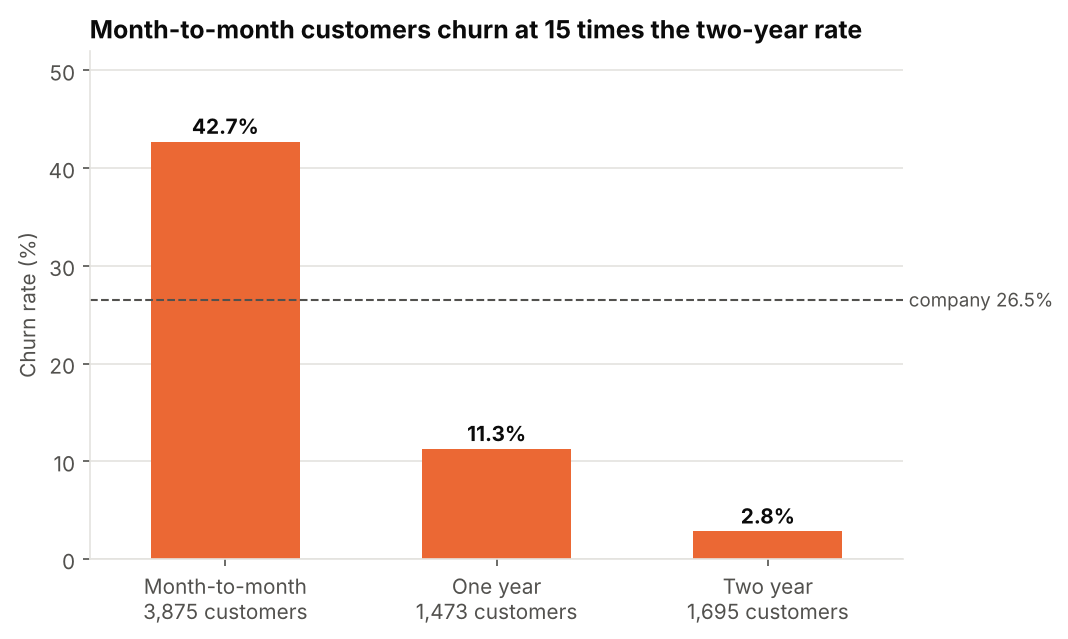

In [ ]:
order = ['Month-to-month', 'One year', 'Two year']
g = rate(eda, 'contract').loc[order]
fig, ax = plt.subplots(figsize=(7, 4.4))
bars = ax.bar(range(3), g['pct'], color=CHURN, width=0.55)
for b, v in zip(bars, g['pct']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%', ha='center', fontweight='bold')
ax.set_xticks(range(3), [f'{c}\n{n:,} customers' for c, n in zip(order, g['n'])])
ax.set_ylim(0, 52); ax.set_ylabel('Churn rate (%)'); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
ax.set_xlim(-0.5, 2.5); overall_line(ax)
ax.set_title('Month-to-month customers churn at 15 times the two-year rate')
save(fig, 'churn_by_contract.png')

**Observation:** Churn is 42.7% on month-to-month, 11.3% on one-year and 2.8% on two-year. Month-to-month customers are 55% of the base but 89% of all churners.
**Business meaning:** Contract type has the biggest spread of any variable we have seen. Part of this is likely selection (people who expect to leave avoid long contracts), so we cannot say a longer contract *causes* retention. It does tell us where the losses are.

### 5.3 When in the customer lifecycle does churn happen?
**Question:** How does the churn rate change as tenure grows? (The 11 customers with tenure 0 are excluded: no billing history yet.)

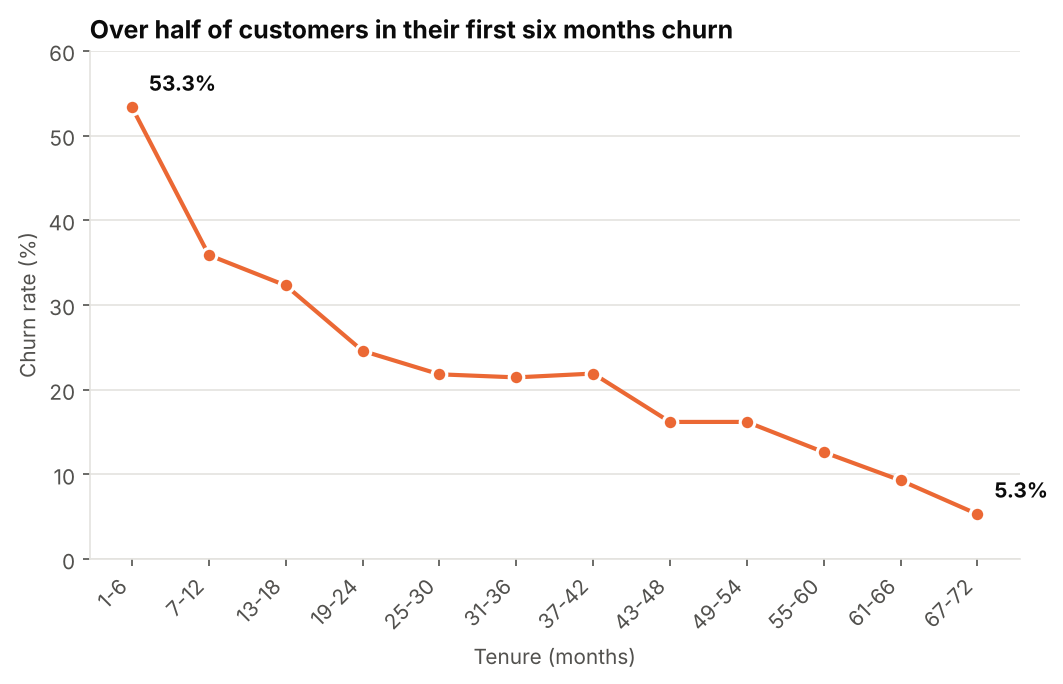

In [ ]:
t = eda[eda.tenure_months >= 1].copy()
t['bucket'] = (t.tenure_months - 1) // 6          # 0 = months 1-6, 1 = months 7-12, ...
g = rate(t, 'bucket')
labels = [f'{b*6+1}-{b*6+6}' for b in g.index]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(range(len(g)), g['pct'], color=CHURN, lw=2, marker='o', ms=7, markeredgecolor='white', markeredgewidth=1.5)
for i in [0, len(g) - 1]:
    ax.annotate(f'{g.pct.iloc[i]:.1f}%', (i, g.pct.iloc[i]), textcoords='offset points', xytext=(8, 8), fontweight='bold')
ax.set_xticks(range(len(g)), labels, rotation=45, ha='right')
ax.set_xlabel('Tenure (months)'); ax.set_ylabel('Churn rate (%)'); ax.set_ylim(0, 60)
ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
ax.set_title('Over half of customers in their first six months churn')
save(fig, 'churn_by_tenure.png')

**Observation:** Churn is 53.3% in months 1-6 and falls steadily to 5.3% in months 67-72. The steepest drop is in the first year.
**Business meaning:** This is a snapshot, not a cohort over time, so the curve mixes survivor effects (people who stay long are by definition people who did not leave). Even so, the first six months stand out as the period where retention effort should be concentrated.

### 5.4 Is the fiber problem just a month-to-month problem?
**Question:** Does the higher churn on fiber optic persist after accounting for contract type?

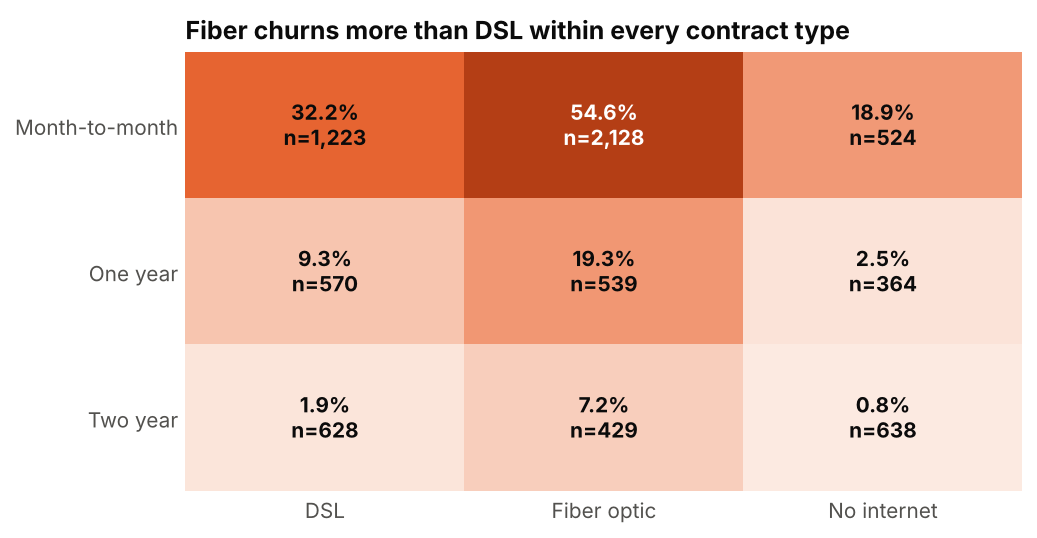

In [ ]:
pv = eda.pivot_table(index='contract', columns='internet_service', values='churn_value', aggfunc='mean').loc[order, ['DSL', 'Fiber optic', 'No']] * 100
cnt = eda.pivot_table(index='contract', columns='internet_service', values='churn_value', aggfunc='size').loc[order, ['DSL', 'Fiber optic', 'No']]
cmap = mpl.colors.LinearSegmentedColormap.from_list('churn', ['#fdeee6', CHURN, '#a8350f'])
fig, ax = plt.subplots(figsize=(7.2, 3.8))
im = ax.imshow(pv.values, cmap=cmap, vmin=0, vmax=60, aspect='auto')
for i in range(3):
    for j in range(3):
        v = pv.values[i, j]
        ax.text(j, i, f'{v:.1f}%\nn={cnt.values[i, j]:,}', ha='center', va='center',
                color='white' if v > 35 else INK, fontweight='bold', fontsize=10)
ax.set_xticks(range(3), ['DSL', 'Fiber optic', 'No internet']); ax.set_yticks(range(3), order)
ax.tick_params(length=0); ax.spines[:].set_visible(False)
ax.set_title('Fiber churns more than DSL within every contract type')
save(fig, 'churn_contract_internet.png')

**Observation:** Fiber churn exceeds DSL churn in every contract row (month-to-month 54.6% vs 32.2%; one-year 19.3% vs 9.3%; two-year 7.2% vs 1.9%). Customers with no internet service churn least.
**Business meaning:** The fiber gap is not explained by contract mix alone. Something about the fiber customer or product (price, reliability, competitor pressure) is associated with extra churn. The data cannot tell us which; that needs customer research.

### 5.5 Is electronic check just a proxy for contract type?
**Question:** Does the higher churn of electronic-check payers remain once we compare within the same contract type?

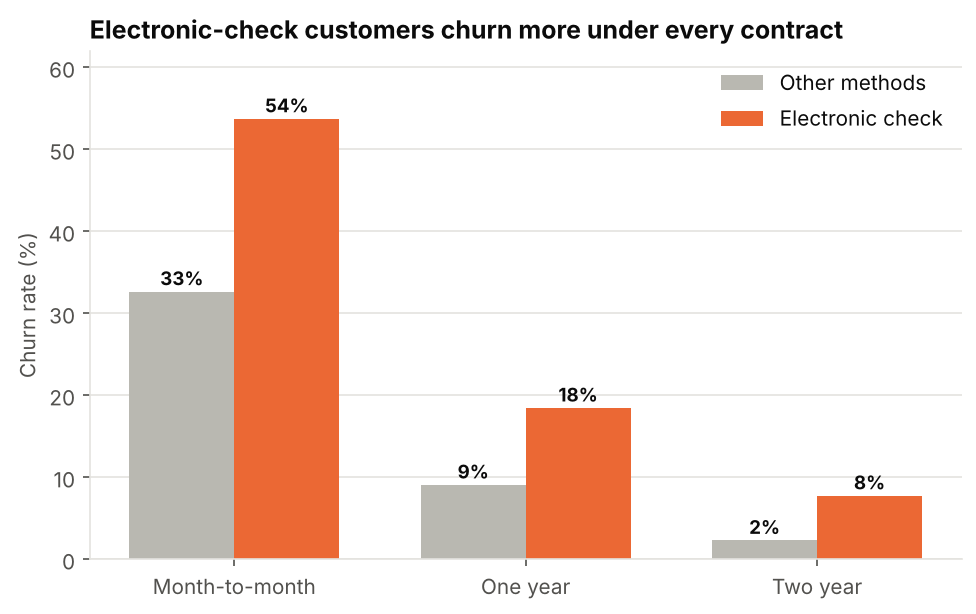

In [ ]:
eda['pay_group'] = np.where(eda.payment_method == 'Electronic check', 'Electronic check', 'Other methods')
g = eda.groupby(['contract', 'pay_group']).churn_value.agg(n='size', pct=lambda s: s.mean() * 100).unstack().loc[order]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
w = 0.36
for k, (grp, col) in enumerate([('Other methods', NEUTRAL), ('Electronic check', CHURN)]):
    xs = np.arange(3) + (k - 0.5) * w
    bars = ax.bar(xs, g['pct'][grp], width=w, color=col, label=grp)
    for b, v in zip(bars, g['pct'][grp]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=9)
ax.set_xticks(range(3), order); ax.set_ylabel('Churn rate (%)'); ax.set_ylim(0, 62)
ax.grid(axis='y', color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False, loc='upper right')
ax.set_title('Electronic-check customers churn more under every contract')
save(fig, 'churn_payment_by_contract.png')

**Observation:** Electronic-check churn is higher within each contract: month-to-month 54% vs about 32-34% for other methods, one-year 18% vs 7-10%, two-year 8% vs 1-3%.
**Business meaning:** Contract type does not fully explain the payment-method gap, so electronic check is a useful warning flag in its own right. We still cannot say it *causes* churn; payment choice may reflect customer type, and other factors not in the data. (This corrects the cautious guess in the Phase 4 SQL comment, which was "probably a proxy for contract". The data says it is not only that.)

### 5.6 Do customers with protection services stay longer?
**Question:** Among customers who have internet service, how does churn change with the number of protection add-ons (online security, online backup, device protection, tech support)?

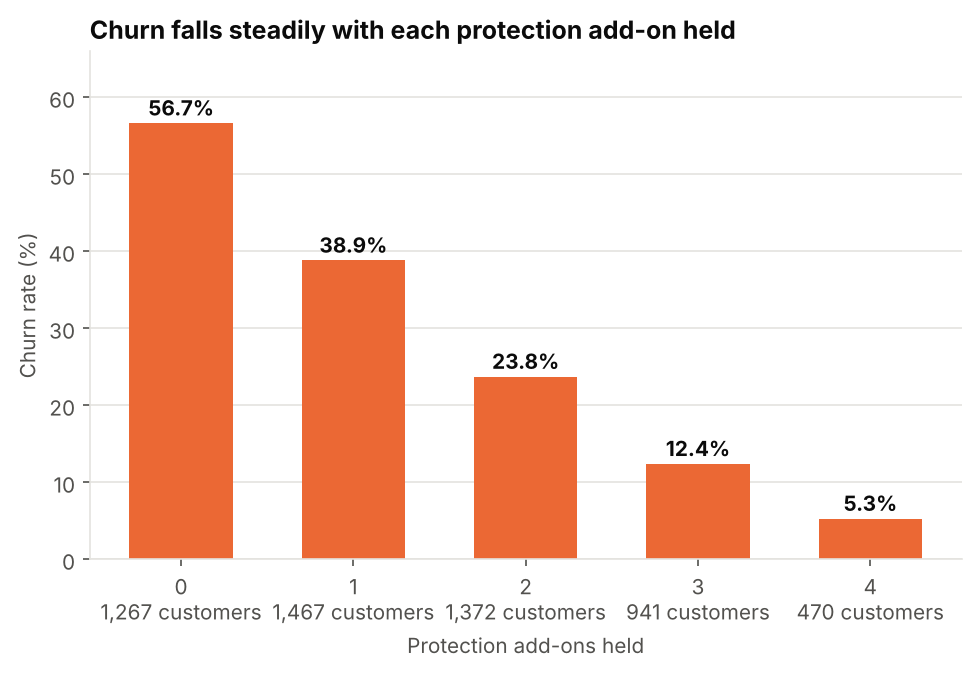

In [ ]:
inet = eda[eda.internet_service != 'No'].copy()
inet['protection_count'] = (inet[['online_security', 'online_backup', 'device_protection', 'tech_support']] == 'Yes').sum(axis=1)
g = rate(inet, 'protection_count')
fig, ax = plt.subplots(figsize=(7.5, 4.4))
bars = ax.bar(g.index, g['pct'], color=CHURN, width=0.6)
for b, v in zip(bars, g['pct']):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
ax.set_xticks(g.index, [f'{i}\n{n:,} customers' for i, n in zip(g.index, g['n'])])
ax.set_xlabel('Protection add-ons held'); ax.set_ylabel('Churn rate (%)'); ax.set_ylim(0, 66)
ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
ax.set_title('Churn falls steadily with each protection add-on held')
save(fig, 'churn_by_protection_services.png')

**Observation:** Churn is 56.7% with no protection add-on and 5.3% with all four (internet customers only). Online security (41.8% without vs 14.6% with) and tech support (41.6% vs 15.2%) show the biggest gaps; streaming TV/movies show almost none (about 34% vs 30%).
**Business meaning:** Customers who hold protection services churn much less. This is an association: engaged customers may simply buy more, and add-ons also raise switching cost. A bundled-trial offer is a testable idea, not a proven fix.

### 5.7 Do churned customers pay more because of price, or because of what they buy?
**Question:** Churners average a higher monthly charge. Does that hold within each internet type?

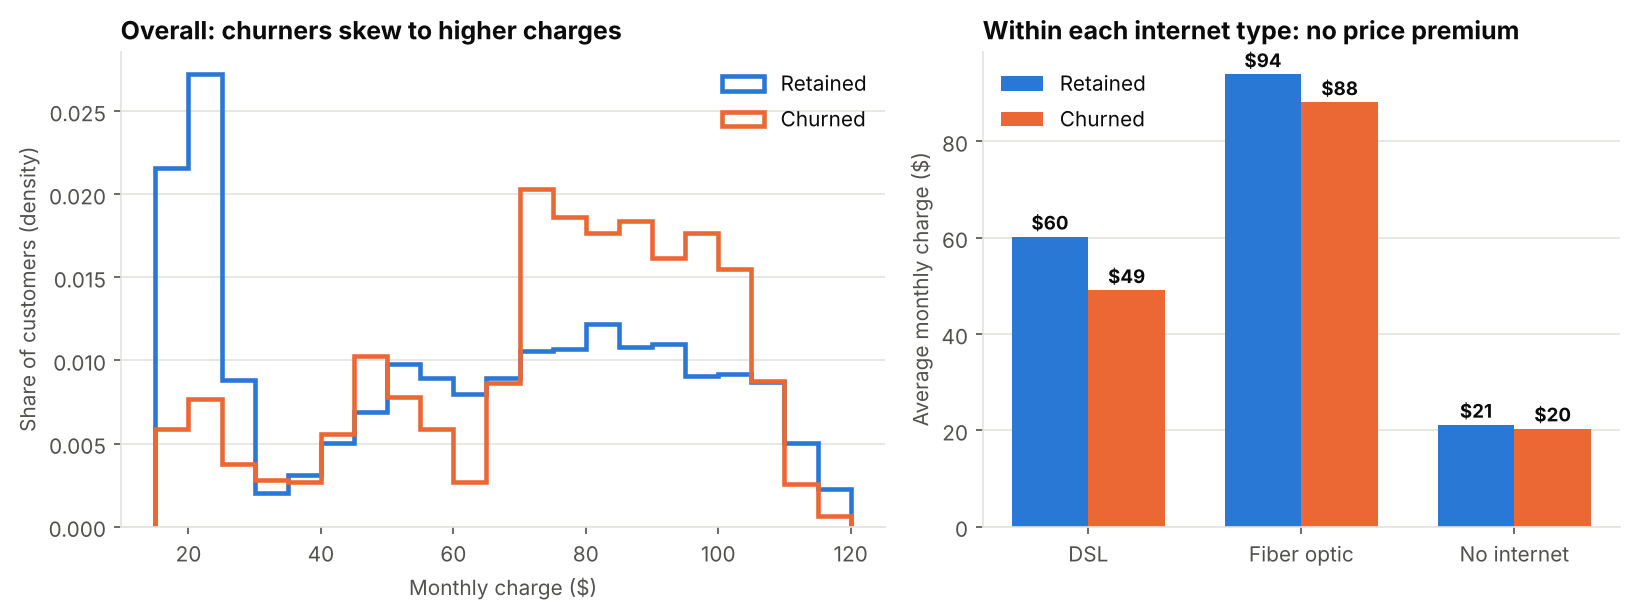

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})
bins = np.arange(15, 125, 5)
for val, col, lab in [(0, STAY, 'Retained'), (1, CHURN, 'Churned')]:
    a1.hist(eda.loc[eda.churn_value == val, 'monthly_charges'], bins=bins, density=True, histtype='step', color=col, linewidth=2.2, label=lab)
a1.set_xlabel('Monthly charge ($)'); a1.set_ylabel('Share of customers (density)')
a1.set_title('Overall: churners skew to higher charges'); a1.legend(frameon=False)
m = eda.groupby(['internet_service', 'churn_value']).monthly_charges.mean().unstack().loc[['DSL', 'Fiber optic', 'No']]
x = np.arange(3); w = 0.36
for k, (val, col, lab) in enumerate([(0, STAY, 'Retained'), (1, CHURN, 'Churned')]):
    bars = a2.bar(x + (k - 0.5) * w, m[val], width=w, color=col, label=lab)
    for b, v in zip(bars, m[val]):
        a2.text(b.get_x() + b.get_width() / 2, v + 1.5, f'${v:.0f}', ha='center', fontsize=9, fontweight='bold')
a2.set_xticks(x, ['DSL', 'Fiber optic', 'No internet']); a2.set_ylabel('Average monthly charge ($)')
a2.set_title('Within each internet type: no price premium'); a2.legend(frameon=False, loc='upper left')
for a in (a1, a2): a.grid(axis='y', color=GRID); a.set_axisbelow(True)
fig.tight_layout()
save(fig, 'monthly_charges_by_churn.png')

**Observation:** Overall, churned customers pay $74 vs $61 for retained. But inside each internet type, churners pay the same or *less*: DSL $49 vs $60, fiber $88 vs $94, no internet $20 vs $21.
**Business meaning:** The overall gap comes from product mix (churners are more often on pricey fiber), not from customers paying more than peers on the same product. This challenges a simple "our prices are too high" story. Only 13% of churners cited price-type reasons (Phase 4). Self-reported reasons and price level should both be examined before cutting prices.

### 5.8 Which demographic groups differ?
**Question:** Do gender, age, partner status or dependents relate to churn?

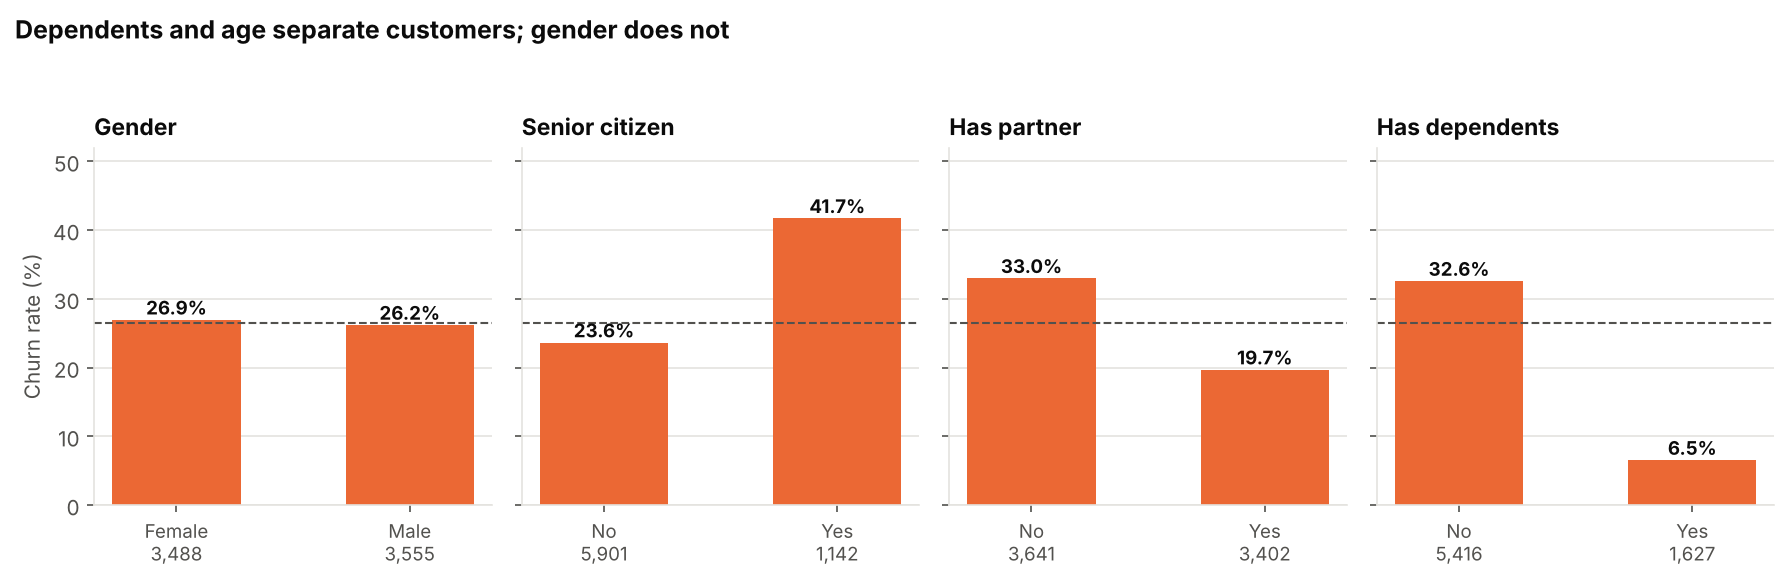

In [ ]:
panels = [('gender', 'Gender'), ('senior_citizen', 'Senior citizen'), ('partner', 'Has partner'), ('dependents', 'Has dependents')]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.9), sharey=True)
for ax, (col, title) in zip(axes, panels):
    g = rate(eda, col)
    bars = ax.bar(range(len(g)), g['pct'], color=CHURN, width=0.55)
    for b, v in zip(bars, g['pct']):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')
    ax.set_xticks(range(len(g)), [f'{i}\n{n:,}' for i, n in zip(g.index, g['n'])], fontsize=9)
    ax.axhline(overall, color=INK2, lw=1, ls='--'); ax.set_title(title, fontsize=11)
    ax.set_ylim(0, 52); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('Churn rate (%)')
fig.suptitle('Dependents and age separate customers; gender does not', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.94))
save(fig, 'churn_demographics.png')

**Observation:** Gender makes no practical difference (26.9% female vs 26.2% male; dashed line = company 26.5%). Seniors churn at 41.7% vs 23.6%. Customers without a partner churn at 33.0% vs 19.7%, and without dependents at 32.6% vs 6.5%.
**Business meaning:** Household stability (dependents, partner) and age are relevant segments; gender is not worth targeting. These variables overlap (seniors often have no dependents), so each bar is not an independent effect. Phase 6 will help separate them.

### 5.9 What about `total_charges`?
**Question:** Does `total_charges` add information beyond tenure?

In [ ]:
print(eda[['tenure_months', 'monthly_charges', 'total_charges', 'churn_value']].corr().round(2))
print()
print(eda.groupby('churn_label')[['total_charges', 'tenure_months']].mean().round(0))

**Observation:** `total_charges` correlates 0.83 with `tenure_months`, because it is essentially tenure x monthly charge. Churners have lower totals ($1,532 vs $2,550) mainly because they stayed fewer months.
**Business meaning:** Do not read "low total charges" as a separate churn driver; it mostly restates short tenure. For revenue-impact work use `monthly_charges`; for lifetime value so far use `total_charges`. In Phase 8, including both with tenure adds redundancy.

## Phase 5 summary: what carries into Phase 6 (hypotheses, not conclusions)
1. Churn differs strongly by contract type (42.7% / 11.3% / 2.8%).
2. Churn falls with tenure; the first six months are the highest risk.
3. Fiber optic and electronic-check customers churn more even within the same contract type.
4. Customers with more protection add-ons churn less.
5. The higher average charge of churners reflects product mix, not a price premium on the same product.
6. Gender shows no difference; age and household (dependents) do.

Phase 6 will test which of these differences are statistically distinguishable from chance, and how large they are.

---
# Phase 6: Statistics
Phase 5 showed *differences*. Statistics asks two further questions: **could this difference be random noise?** (significance) and **how big is it?** (effect size).

> **Statistical significance ≠ business significance ≠ causation.**
> - *Significant* means "unlikely to be pure chance". With 7,043 customers, even tiny differences become significant.
> - *Business significant* means "large enough to change a decision". That needs effect size and money, not a p-value.
> - *Causal* means "changing X would change churn". Nothing in this snapshot can establish that.

For each test below: **hypothesis → assumptions → why this test → interpretation → limitations.**

In [ ]:
from scipy import stats
ALPHA = 0.05

### 6.1 Confidence intervals for churn rates
- **Question:** How precisely do we know the churn rate? "26.5%" is one sample's estimate.
- **What a 95% CI means:** if we repeated the sampling many times, about 95% of intervals built this way would contain the true rate. It is *not* "95% probability the true rate is in this range".
- **Method:** Wilson interval for a proportion. It behaves better than the textbook normal approximation for small groups or rates near 0% (like the 2.8% two-year group).
- **Assumptions:** customers are independent; each is churned or not; the 7,043 rows behave like a sample from a wider process.
- **Limitations:** this is one company, one period. If these 7,043 are the *entire* customer base, the CI describes uncertainty about the underlying process, not about this exact quarter. It captures sampling noise only, not bias.

In [ ]:
def wilson(k, n):
    ci = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method='wilson')
    return ci.low * 100, ci.high * 100

k, n = eda.churn_value.sum(), len(eda)
lo, hi = wilson(k, n)
print(f'Overall churn: {k/n*100:.2f}%   95% CI {lo:.1f}% to {hi:.1f}%')

order = ['Month-to-month', 'One year', 'Two year']
rows = []
for c in order:
    g = eda[eda.contract == c]
    lo, hi = wilson(g.churn_value.sum(), len(g))
    rows.append((c, len(g), g.churn_value.mean() * 100, lo, hi))
ci_tbl = pd.DataFrame(rows, columns=['contract', 'n', 'churn_pct', 'ci_low', 'ci_high']).round(1)
ci_tbl

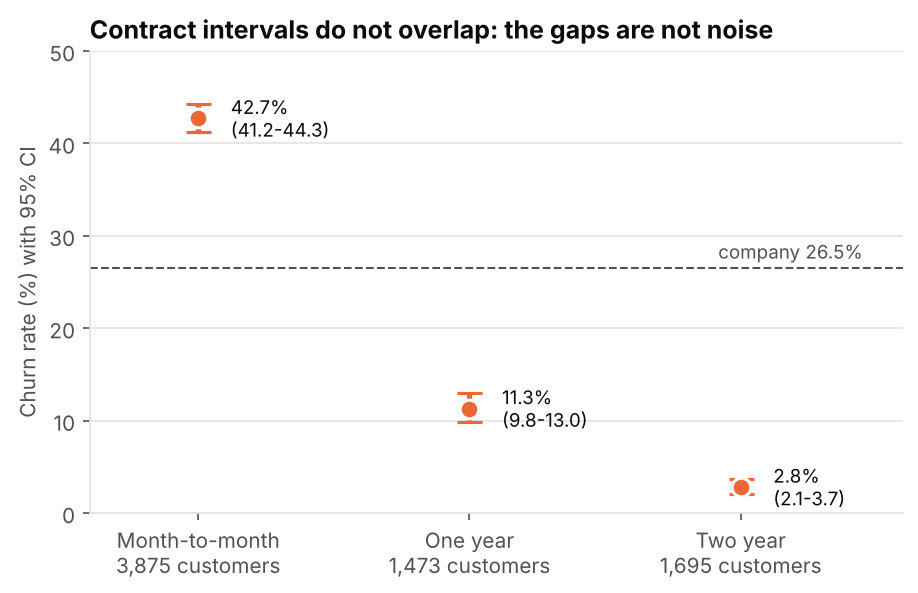

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
ax.errorbar(x, ci_tbl.churn_pct, yerr=[ci_tbl.churn_pct - ci_tbl.ci_low, ci_tbl.ci_high - ci_tbl.churn_pct],
            fmt='o', color=CHURN, ecolor=CHURN, elinewidth=2.5, capsize=6, ms=9, markeredgecolor='white', markeredgewidth=1.5)
for xi, r in zip(x, ci_tbl.itertuples()):
    ax.text(xi + 0.12, r.churn_pct, f'{r.churn_pct:.1f}%\n({r.ci_low:.1f}-{r.ci_high:.1f})', va='center', fontsize=9)
ax.axhline(overall, color=INK2, lw=1, ls='--'); ax.text(2.45, overall + 1, f'company {overall:.1f}%', ha='right', color=INK2, fontsize=9)
ax.set_xticks(x, [f'{c}\n{n:,} customers' for c, n in zip(ci_tbl.contract, ci_tbl.n)])
ax.set_xlim(-0.4, 2.6); ax.set_ylim(0, 50); ax.set_ylabel('Churn rate (%) with 95% CI')
ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
ax.set_title('Contract intervals do not overlap: the gaps are not noise')
save(fig, 'churn_ci_by_contract.png')

**Interpretation:** Overall churn is 26.5% (95% CI 25.5% to 27.6%). The three contract intervals (41.2-44.3%, 9.8-13.0%, 2.1-3.7%) are far apart, so contract differences are not sampling noise.
**Business meaning:** The intervals are narrow enough that planning on "about a quarter of customers churn per period" is safe, as long as the future resembles this snapshot.

### 6.2 Chi-square test of independence (categorical variable vs churn)
- **Hypotheses:** H0: churn and the variable are independent (churn rate is the same in every group). H1: churn rate differs between groups.
- **Why this test:** both variables are categorical, and we compare counts in a contingency table (group x churned/retained). A t-test would be wrong here: there is no numeric mean to compare.
- **Assumptions:** observations are independent (one row per customer); every *expected* count is at least 5 (we check this).
- **Effect size:** p-values only say "not chance". **Cramér's V** says how strong the association is, from 0 (none) to 1 (perfect). With a 2-column outcome, rough guide: 0.1 small, 0.3 medium, 0.5 large.
- **Multiple tests:** we run 16 tests. At alpha 0.05, about one false positive is expected by chance alone, so we apply a **Bonferroni** threshold (0.05 / 16 = 0.0031).
- **Subsets:** add-on services (security, backup, ...) are only meaningful for customers who *have* internet, and multiple lines only for customers with phone. Including everyone would mix "declined" with "could not have it" (the Phase 3 caveat), so we test those on the relevant subset.
- **Limitations:** significance depends on sample size; chi-square says nothing about direction or cause. Variables overlap (e.g. dependents and partner), so these are not independent effects.

In [ ]:
def chi_sq(df, col):
    ct = pd.crosstab(df[col], df.churn_value)
    chi2, p, dof, expected = stats.chi2_contingency(ct, correction=False)
    v = np.sqrt(chi2 / ct.values.sum() / (min(ct.shape) - 1))     # Cramer's V
    return dict(n=len(df), chi2=chi2, p=p, cramers_v=v, min_expected=expected.min())

inet = eda[eda.internet_service != 'No']
phone = eda[eda.phone_service == 'Yes']
tests = []
for c in ['gender', 'senior_citizen', 'partner', 'dependents', 'phone_service', 'internet_service',
          'contract', 'paperless_billing', 'payment_method']:
    tests.append({'variable': c, **chi_sq(eda, c)})
for c in ['online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies']:
    tests.append({'variable': c + ' (internet customers)', **chi_sq(inet, c)})
tests.append({'variable': 'multiple_lines (phone customers)', **chi_sq(phone, 'multiple_lines')})

chi = pd.DataFrame(tests).sort_values('cramers_v', ascending=False).reset_index(drop=True)
bonf = ALPHA / len(chi)
chi['significant_bonferroni'] = chi.p < bonf
chi['effect'] = pd.cut(chi.cramers_v, [0, 0.1, 0.3, 0.5, 1], labels=['negligible', 'small', 'medium', 'large'])
print(f'Bonferroni threshold: {bonf:.4f};  smallest expected count in any test: {chi.min_expected.min():.0f} (need >= 5)')
chi[['variable', 'n', 'chi2', 'p', 'cramers_v', 'effect', 'significant_bonferroni']].round(4)

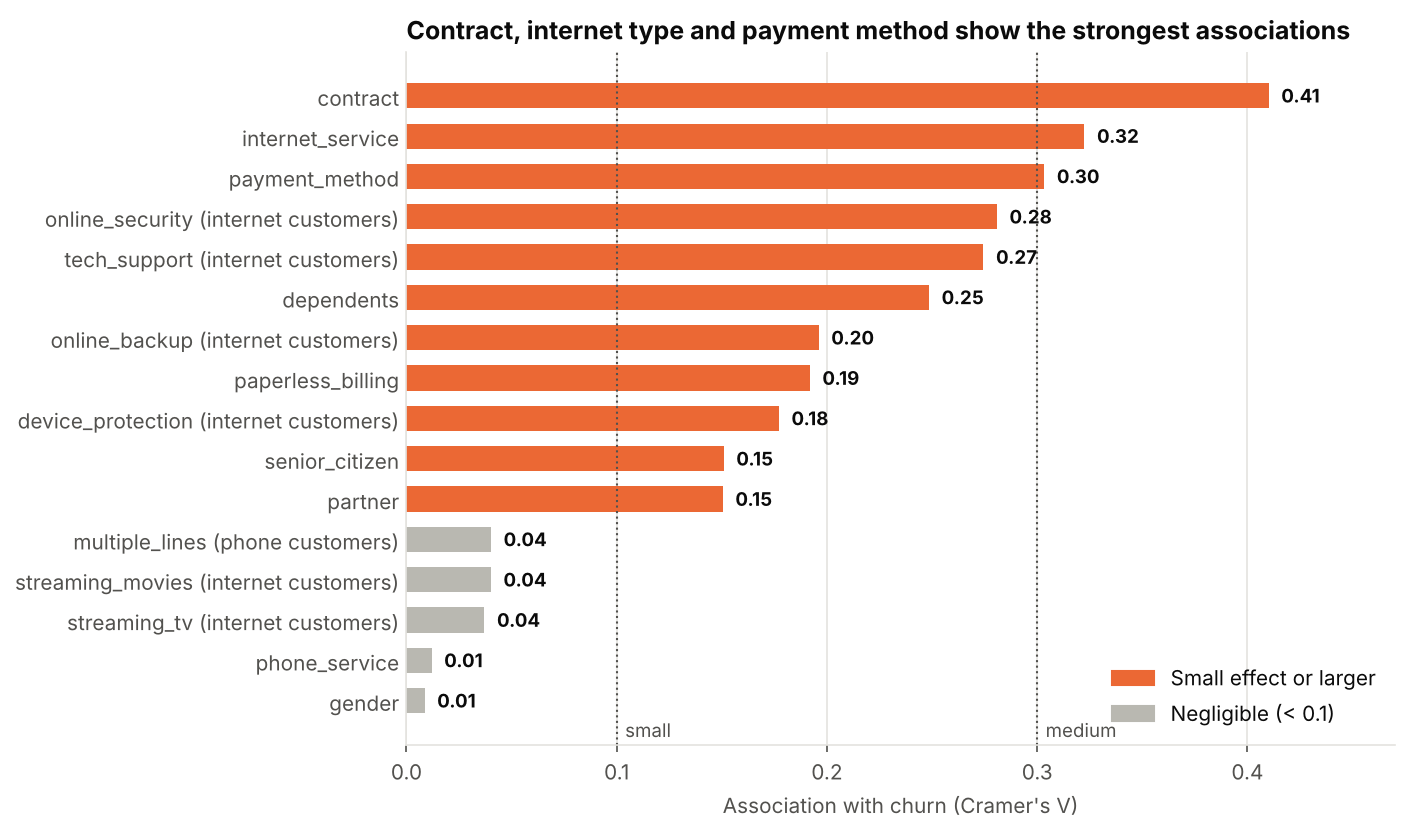

In [ ]:
d = chi.sort_values('cramers_v')
colors = [CHURN if v >= 0.1 else NEUTRAL for v in d.cramers_v]
fig, ax = plt.subplots(figsize=(8.5, 6))
bars = ax.barh(d.variable, d.cramers_v, color=colors, height=0.62)
for b, v in zip(bars, d.cramers_v):
    ax.text(v + 0.006, b.get_y() + b.get_height() / 2, f'{v:.2f}', va='center', fontsize=9, fontweight='bold')
for x0, lab in [(0.1, 'small'), (0.3, 'medium')]:
    ax.axvline(x0, color=INK2, lw=1, ls=':'); ax.text(x0 + 0.004, -0.9, lab, color=INK2, fontsize=9)
ax.set_xlim(0, 0.47); ax.set_xlabel("Association with churn (Cramer's V)")
ax.grid(axis='x', color=GRID); ax.set_axisbelow(True); ax.tick_params(axis='y', length=0)
ax.set_title('Contract, internet type and payment method show the strongest associations')
ax.legend(handles=[mpl.patches.Patch(color=CHURN, label='Small effect or larger'), mpl.patches.Patch(color=NEUTRAL, label='Negligible (< 0.1)')],
          frameon=False, loc='lower right')
save(fig, 'churn_drivers_effect_size.png')

**Interpretation:**
- All expected counts are well above 5, so the test is valid.
- **Strongest associations:** contract (V = 0.41, medium-to-large), internet service (0.32), payment method (0.30), online security (0.28), tech support (0.27), dependents (0.25).
- **Not significant:** gender (p = 0.47) and phone service (p = 0.32). With 7,043 customers, any real gender effect is small; the interval around the gender gap is narrow.
- **Significant but negligible:** multiple lines, streaming movies and streaming TV have p < 0.01 but V of about 0.04. They are statistically distinguishable from zero and practically almost useless. (After the Bonferroni correction, streaming TV no longer clears the bar; the others only just do.) This is the cleanest example of significance without business importance.

**Business meaning:** Rank retention focus by *effect size*, not by p-value. Contract, internet type, payment method, and the security/support add-ons deserve attention; gender, phone service and streaming do not.
**Limitation:** Cramér's V does not control for overlap between variables. Phase 8 (modelling) handles that better.

### 6.3 Comparing numeric variables: t-test or Mann-Whitney, plus effect size
- **Question:** Do churned and retained customers differ in `tenure_months`, `monthly_charges`, `total_charges`?
- **Hypotheses:** H0: the two groups have the same distribution (same mean for the t-test). H1: they differ.
- **Which test:**
  - **Welch's t-test** compares means and does not assume equal variances. Assumption: the sampling distribution of the mean is roughly normal. With about 1,900 and 5,200 customers the Central Limit Theorem makes this acceptable even for skewed data.
  - **Mann-Whitney U** compares whole distributions using ranks. It is safer when data are skewed. Churners' tenure is skewed (skewness about 1.2), so Mann-Whitney is the primary test for tenure; we run both and see whether they agree.
- **Effect sizes:** **Cohen's d** (difference in standard deviations; 0.2 small, 0.5 medium, 0.8 large) and a plain-language **probability of superiority**: the chance that a randomly chosen churner has a *higher* value than a randomly chosen retained customer (50% = no difference).
- **Limitations:** both tests treat customers as independent. A tiny p-value here will happen with almost any gap at this sample size, so look at d and the medians.

In [ ]:
rows = []
for c in ['tenure_months', 'monthly_charges', 'total_charges']:
    a = eda.loc[eda.churn_value == 1, c]            # churned
    b = eda.loc[eda.churn_value == 0, c]            # retained
    t = stats.ttest_ind(a, b, equal_var=False)
    u = stats.mannwhitneyu(a, b, alternative='two-sided')
    pooled_sd = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    rows.append({'variable': c,
                 'median_churned': a.median(), 'median_retained': b.median(),
                 'mean_churned': a.mean(), 'mean_retained': b.mean(),
                 'skew_churned': a.skew(),
                 'welch_p': t.pvalue, 'mannwhitney_p': u.pvalue,
                 'cohens_d': (a.mean() - b.mean()) / pooled_sd,
                 'prob_churner_higher': u.statistic / (len(a) * len(b))})
num = pd.DataFrame(rows).set_index('variable')
num.round(3).T

**Interpretation:**
- **Tenure:** churners' median is 10 months vs 38 for retained. Cohen's d = -0.85 (large). There is a 74% chance a random churner has *shorter* tenure than a random retained customer (probability of superiority about 26%). Both tests agree (p effectively 0).
- **Monthly charges:** median $79.65 vs $64.43; d = +0.45 (small-to-medium); a random churner has a higher charge about 62% of the time.
- **Total charges:** d = -0.46, but this largely restates tenure (correlated 0.83), so it is not an independent finding.

**Business meaning:** Tenure is the strongest numeric signal, and it is large in practical terms. The monthly-charge difference is real but only moderate, and section 6.5 shows it is mostly product mix.

### 6.4 Correlation
- **Question:** How strongly does each numeric variable move with churn, and are the numeric variables redundant with each other?
- **Method:** **Spearman** rank correlation (it handles skewed data and monotone, not just straight-line, relationships). With a 0/1 outcome the Pearson version is the *point-biserial* correlation; we show both.
- **Hypotheses:** H0: no monotone relationship (rho = 0).
- **Interpretation guide:** |rho| below 0.1 negligible, 0.1-0.3 weak, 0.3-0.5 moderate, above 0.5 strong. These are conventions, not laws.
- **Limitations:** correlation with a binary outcome understates strength (the outcome has only two values), and a correlation between two features (tenure vs total charges) signals redundancy, not a driver.

In [ ]:
cols = ['tenure_months', 'monthly_charges', 'total_charges']
out = pd.DataFrame({
    'spearman_rho': [stats.spearmanr(eda[c], eda.churn_value)[0] for c in cols],
    'spearman_p':   [stats.spearmanr(eda[c], eda.churn_value)[1] for c in cols],
    'pearson_r':    [stats.pearsonr(eda[c], eda.churn_value)[0] for c in cols]}, index=cols)
print(out.round(3))
print()
print('Correlation among the numeric features (Spearman):')
print(eda[cols].corr(method='spearman').round(2))

**Interpretation:** Tenure has a moderate negative correlation with churn (rho about -0.37). Monthly charges have a weak positive one (about +0.19). Total charges are weakly negative (about -0.23) and correlate about 0.89 (Spearman; 0.83 Pearson) with tenure.
**Business meaning:** Longer relationships go with lower churn. High monthly charge goes with more churn only weakly. Tenure and total charges carry overlapping information, so we should not treat them as two separate drivers.

### 6.5 Does the monthly-charge difference survive a like-for-like comparison?
- **Why this matters:** In Phase 5 churners paid more overall, yet *less* within each internet type. A single overall test can therefore point to the wrong conclusion. This is a **confounding / mix** effect: internet type is linked to both the price and the churn.
- **Method:** repeat Mann-Whitney within each internet-service group (a *stratified* comparison). Hypotheses and assumptions as in 6.3, applied to each stratum.
- **Limitations:** this only controls for internet type. Other differences (tenure, contract) remain. A regression model in Phase 8 can adjust for several at once.

In [ ]:
rows = []
for s, g in eda.groupby('internet_service'):
    a = g.loc[g.churn_value == 1, 'monthly_charges']; b = g.loc[g.churn_value == 0, 'monthly_charges']
    rows.append({'internet_service': s, 'n_churned': len(a), 'n_retained': len(b),
                 'mean_churned': a.mean(), 'mean_retained': b.mean(),
                 'diff_churned_minus_retained': a.mean() - b.mean(),
                 'mannwhitney_p': stats.mannwhitneyu(a, b).pvalue})
pd.DataFrame(rows).set_index('internet_service').round(3)

**Interpretation:** Within each internet type, churned customers pay *less* than retained ones (DSL -$11, fiber -$6, no internet -$1), and all three differences are statistically significant, although the no-internet gap is under $1. The overall "churners pay more" result reverses once we compare like with like.
**Business meaning:** Do not conclude that high prices drive churn from the overall average. The overall gap is explained by churn being concentrated in the pricier fiber product. The reasons *why* fiber customers leave need separate investigation.

### 6.6 Business significance: how big is the gap, in customers and money?
- **Question:** Beyond "significant", how large is the month-to-month gap, and how does it compare with a gap that is significant but trivial?
- **Method:** risk difference (percentage-point gap) with a 95% CI, and relative risk (how many times higher).
- **Limitations:** the "excess churners" figure below is a way to size the gap, not a saving we could capture. Month-to-month customers differ from others in many ways, and not all of the gap could be closed by any action.

In [ ]:
def risk_gap(mask):
    p1, p2 = eda.churn_value[mask].mean(), eda.churn_value[~mask].mean()
    n1, n2 = mask.sum(), (~mask).sum()
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return p1 * 100, p2 * 100, (p1 - p2) * 100, ((p1 - p2) - 1.96 * se) * 100, ((p1 - p2) + 1.96 * se) * 100, p1 / p2, n1

for label, mask in [('Month-to-month vs other contracts', eda.contract == 'Month-to-month'),
                    ('Streaming TV (internet customers) yes vs no', None)]:
    if mask is None:
        m = (eda.internet_service != 'No') & (eda.streaming_tv == 'Yes')
        sub = eda[eda.internet_service != 'No']
        p1, p2 = sub.churn_value[sub.streaming_tv == 'Yes'].mean(), sub.churn_value[sub.streaming_tv == 'No'].mean()
        print(f'{label}: {p1*100:.1f}% vs {p2*100:.1f}%  (gap {(p1-p2)*100:+.1f} points)')
    else:
        p1, p2, gap, lo, hi, rr, n1 = risk_gap(mask)
        print(f'{label}: {p1:.1f}% vs {p2:.1f}%  gap {gap:.1f} points (95% CI {lo:.1f} to {hi:.1f}), relative risk {rr:.1f}x')
        print(f'   => about {gap/100*n1:,.0f} more churners among {n1:,} month-to-month customers than if they churned at the other-contract rate')

**Interpretation:** Month-to-month customers churn at 42.7% vs 6.8% for other contracts: a gap of 36.0 points (95% CI 34.2 to 37.7), 6.3 times higher. That is about 1,390 more churners than if they behaved like other-contract customers. By contrast, streaming TV users churn at 30.1% vs 33.5%: a 3.5-point gap that is statistically detectable but small.
**Business meaning:** Both gaps are "significant"; only one is big enough to build a retention programme around.

### 6.7 What these tests do *not* tell us (causation)
Every result above is an **association in a single snapshot**. Reasons we cannot say "X causes churn":
- **Confounding:** a third factor may drive both (the fiber price result showed this).
- **Selection:** customers who expect to leave avoid long contracts, so "month-to-month causes churn" may be backwards.
- **Reverse causation:** a customer planning to leave may drop their add-ons first, instead of add-ons preventing churn.
- **No intervention:** nobody was randomly assigned a contract, payment method or add-on.
- **Self-reported reasons** (`churn_reason`) are one customer's explanation, not an experiment.

**What would support a causal claim:** a randomised pilot (e.g. offer a discounted annual contract or a security/support bundle to a random half of at-risk month-to-month customers and compare churn), or careful quasi-experimental designs with data over time.

**Rule for the rest of the project:** recommendations will be worded as *"target X, test Y"*, never *"X causes churn"*.

## Phase 6 summary

| Finding | Statistically supported? | Business-significant? | Causal? |
|---|---|---|---|
| Month-to-month churn far above other contracts | Yes (V = 0.41) | Yes (gap of 36 points, about 89% of churners) | Not shown |
| Fiber and electronic check above average | Yes (V = 0.32, 0.30) | Yes | Not shown |
| Short tenure goes with churn | Yes (d = -0.85) | Yes | Not shown |
| Security / tech-support add-ons go with lower churn | Yes (V = 0.28, 0.27) | Yes | Not shown; possible reverse causation |
| Churners pay more | Overall yes; reverses within internet type | Misleading | No |
| Gender, phone service | No | No | No |
| Streaming TV / movies, multiple lines | Marginal | No (V about 0.04) | No |

---
# Phase 7: Feature Engineering
A feature is a new column built from existing ones to make a business pattern easier to see, query or model. Rules we follow:
1. **Justified:** there is a business or evidence reason (not "more columns is better").
2. **No leakage:** a feature used for *prediction* must be knowable *before* the customer churns. Anything built from the churn outcome is for description only and is labelled so.
3. **Documented:** every feature says how it is built and why.
4. **Honest:** if a feature does not work, we say so.

| Feature | Built from | Why it might help |
|---|---|---|
| `tenure_band` | tenure_months | Churn is non-linear in tenure; bands give readable lifecycle stages |
| `service_count`, `protection_count` | service columns | Test whether breadth of relationship relates to churn |
| `customer_value_segment` | monthly_charges | Prioritise by revenue, not just headcount |
| `contract_risk_group` | contract | Ordered label so tables and charts sort sensibly |
| `risk_flag_count`, `risk_level` | 5 yes/no risk flags | A simple, explainable scorecard instead of a black box |
| `segment_churn_rate`, `revenue_at_risk_monthly` | segment churn history x charges | Size the money at stake (description only, outcome-based) |

In [ ]:
ENGINEERED = ['tenure_band', 'service_count', 'protection_count', 'customer_value_segment', 'contract_risk_group',
              'risk_flag_count', 'risk_level', 'segment_churn_rate', 'revenue_at_risk_monthly']
fe = pd.read_csv('../data/clean/customer_churn_clean.csv', dtype={'zip_code': str})
fe = fe[[c for c in fe.columns if c not in ENGINEERED]]     # lets this section be re-run safely
print(fe.shape)

### 7.1 `tenure_band`
- **Why:** Phase 5 showed churn falls steeply in the first year and flattens later. Bands turn a 0-72 number into lifecycle stages a manager can act on ("new customers", "established").
- **Design:** 0-12, 13-24, 25-48, 49-72 months. Uneven widths are deliberate: the first year is where churn changes fastest, so it deserves finer resolution. The same bands are used in the SQL files, so the numbers reconcile.
- **Note:** a banded feature loses detail. For modelling in Phase 8 we will keep the raw `tenure_months` as well.

In [ ]:
fe['tenure_band'] = pd.cut(fe.tenure_months, bins=[-1, 12, 24, 48, 72],
                          labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months']).astype(str)
fe.groupby('tenure_band').churn_value.agg(customers='size', churn_rate=lambda s: round(s.mean() * 100, 1))

### 7.2 `service_count` and `protection_count`
- **Hypothesis:** customers with more services are more embedded and churn less.
- **Build:** `service_count` = phone + internet + multiple lines + six add-ons (0 to 9). `protection_count` = just the four protection services (security, backup, device protection, tech support), counted only for internet customers (as in Phase 5).
- **We test the hypothesis before keeping the feature.**

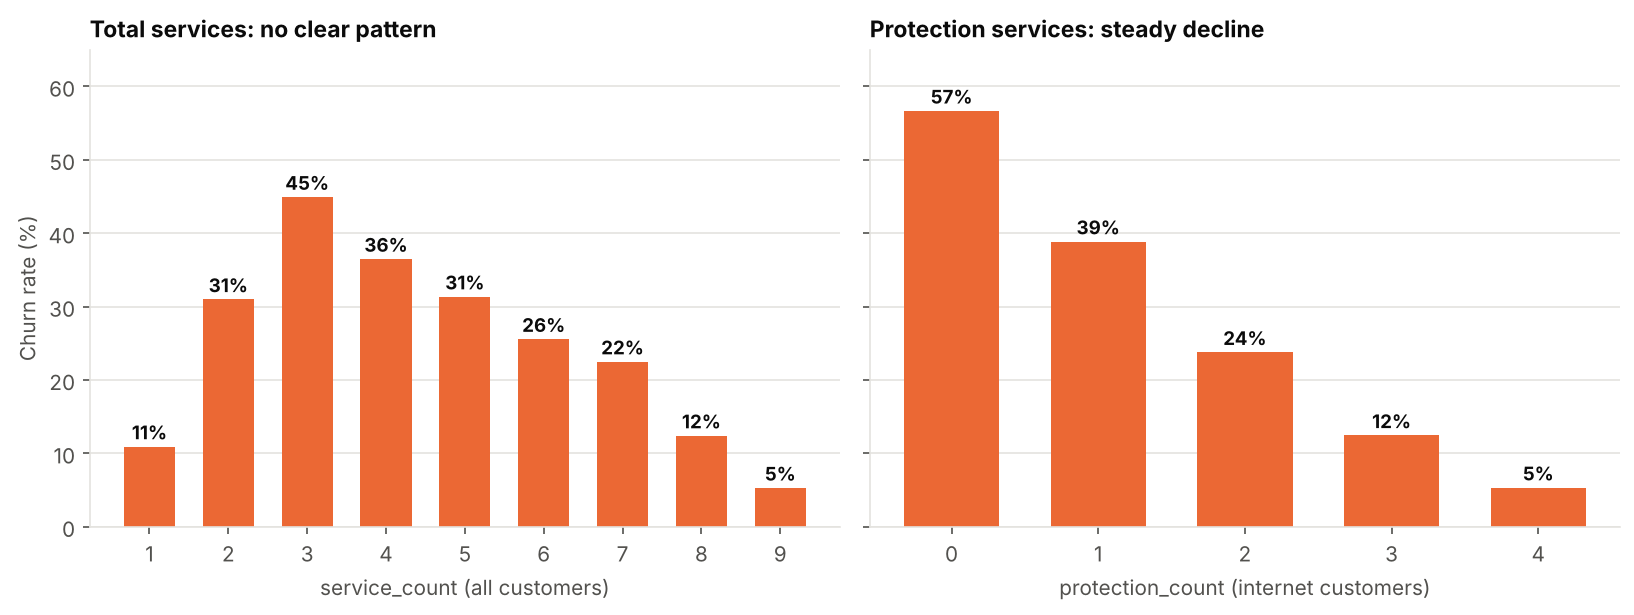

In [ ]:
add_all = ['online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies']
protect = ['online_security', 'online_backup', 'device_protection', 'tech_support']
fe['service_count'] = ((fe.phone_service == 'Yes').astype(int) + (fe.internet_service != 'No').astype(int)
                       + (fe.multiple_lines == 'Yes').astype(int) + (fe[add_all] == 'Yes').sum(axis=1))
fe['protection_count'] = (fe[protect] == 'Yes').sum(axis=1)

sc = fe.groupby('service_count').churn_value.agg(n='size', pct=lambda s: s.mean() * 100)
pc = fe[fe.internet_service != 'No'].groupby('protection_count').churn_value.agg(n='size', pct=lambda s: s.mean() * 100)
print('correlation of service_count with churn:', round(fe.service_count.corr(fe.churn_value), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, g, ttl, xl in [(axes[0], sc, 'Total services: no clear pattern', 'service_count (all customers)'),
                       (axes[1], pc, 'Protection services: steady decline', 'protection_count (internet customers)')]:
    bars = ax.bar(g.index, g.pct, color=CHURN, width=0.65)
    for b, v in zip(bars, g.pct):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.0f}%', ha='center', fontsize=9, fontweight='bold')
    ax.set_xticks(g.index); ax.set_xlabel(xl); ax.set_title(ttl, fontsize=11)
    ax.set_ylim(0, 65); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('Churn rate (%)')
fig.tight_layout()
save(fig, 'feature_service_vs_protection.png')

**Observation:** `service_count` rises then falls: churn is 10.9% at 1 service, peaks at 44.9% at 3 services, and drops to 5.3% at 9. Its overall correlation with churn is about -0.02. `protection_count` falls steadily from 56.7% (none) to 5.3% (all four).
**Business meaning:** Counting every service mixes opposite effects. Customers with 1 service are 94% phone-only (low churn); customers with 3 services are all internet customers (51% fiber) and 48% of them have no protection add-on (high churn). The hypothesis "more services = more loyal" is **wrong as stated**; `protection_count` is the useful feature. We keep `service_count` in the dataset (the brief asked for it, and it shows the pitfall) but will not rely on it. Interview point: a feature that sounds sensible can fail when you check it.

### 7.3 `customer_value_segment`
- **Why:** Phase 4 showed 81% of lost revenue came from the highest-paying customers. A value label lets the dashboard show "high-value, high-risk" groups (Power BI page 3).
- **Build:** by current monthly charge: Low (under $35), Mid ($35 to under $70), High ($70+). This is simple, explainable, and consistent with the SQL. I deliberately did *not* also create a separate "monthly charge band" column, because it would be the same grouping under a second name.
- **Limitation:** value here means *current revenue*, not profit or lifetime value. The dataset's `cltv` column is not used: its construction is undocumented and it may be tied to IBM's own churn modelling.

In [ ]:
fe['customer_value_segment'] = pd.cut(fe.monthly_charges, bins=[0, 35, 70, np.inf], right=False,
                                      labels=['1 Low value', '2 Mid value', '3 High value']).astype(str)
seg = fe.groupby('customer_value_segment').agg(customers=('churn_value', 'size'),
                                               revenue=('monthly_charges', 'sum'),
                                               churn_rate=('churn_value', lambda s: s.mean() * 100))
seg['revenue_share_pct'] = seg.revenue / seg.revenue.sum() * 100
seg.round(1)

**Observation:** High-value customers are 51% of customers, 71% of monthly revenue, and churn at 35.5% (vs 10.9% for Low value).
**Business meaning:** The most valuable half of the base is also the least stable, which is why churn costs more revenue than headcount suggests.

### 7.4 `contract_risk_group`
- **Why:** Contract type is the strongest single association (Phase 6). An ordered label (1 Low, 2 Medium, 3 High) makes tables and charts sort in a meaningful order, and gives non-technical users a risk vocabulary.
- **Honesty note:** this is a relabelling of `contract`, so it adds no new information for a model. It exists for communication. The mapping follows the Phase 5/6 evidence (which means it is not independent of the churn data); for modelling we use `contract` itself.

In [ ]:
fe['contract_risk_group'] = fe.contract.map({'Two year': '1 Low', 'One year': '2 Medium', 'Month-to-month': '3 High'})
fe.groupby('contract_risk_group').churn_value.agg(customers='size', churn_rate=lambda s: round(s.mean() * 100, 1))

### 7.5 `risk_flag_count` and `risk_level`: an explainable scorecard
- **Why:** Before any machine learning, can simple rules rank customers by risk? A scorecard is transparent, so a retention manager can see exactly why someone is flagged.
- **Build:** one point for each flag, chosen from the Phase 5/6 evidence:
  1. month-to-month contract
  2. tenure of 12 months or less
  3. fiber optic internet
  4. electronic check payment
  5. internet customer with no protection add-ons
  
  `risk_level`: 0-1 flags = Low, 2 = Medium, 3 = High, 4-5 = Very high.
- **Caveats:** (a) the flags were chosen *after* looking at this same data, so the separation shown is **optimistic**; Phase 8 must test it on held-out data. (b) the flags overlap (month-to-month customers are also more often new, on fiber and on e-check), so counting them double-counts shared information. (c) each flag uses only information available before churn, so it is usable for prediction, but the *choice* of flags is informed by the outcome.

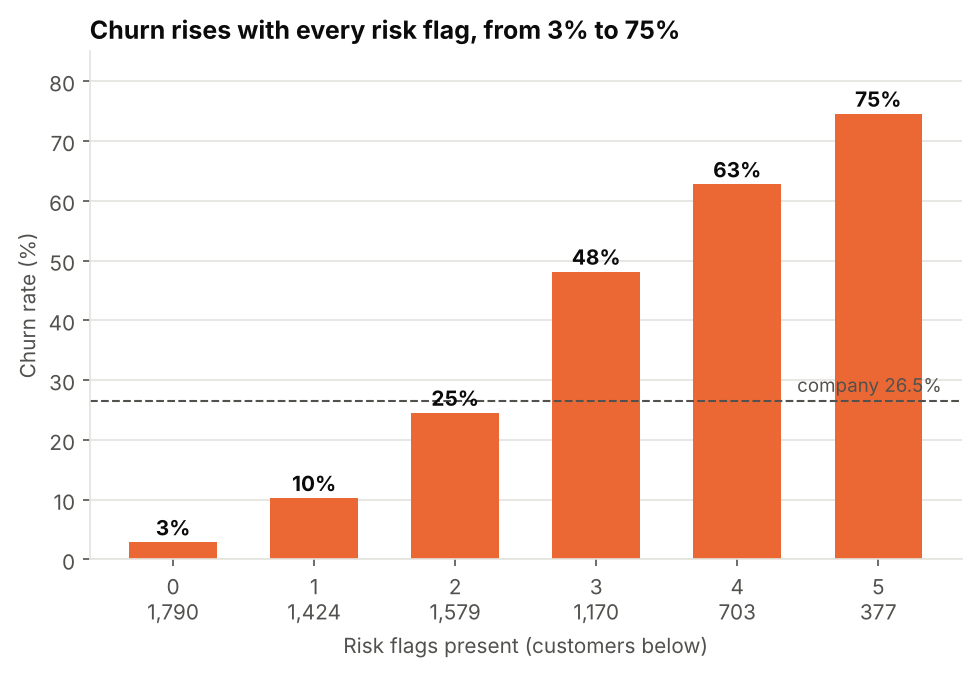

In [ ]:
has_inet = fe.internet_service != 'No'
flags = pd.DataFrame({
    'month_to_month': fe.contract == 'Month-to-month',
    'tenure_le_12':   fe.tenure_months <= 12,
    'fiber':          fe.internet_service == 'Fiber optic',
    'e_check':        fe.payment_method == 'Electronic check',
    'no_protection':  has_inet & (fe.protection_count == 0)})
fe['risk_flag_count'] = flags.sum(axis=1)
fe['risk_level'] = pd.cut(fe.risk_flag_count, bins=[-1, 1, 2, 3, 5],
                          labels=['1 Low', '2 Medium', '3 High', '4 Very high']).astype(str)

by_flag = fe.groupby('risk_flag_count').churn_value.agg(n='size', pct=lambda s: s.mean() * 100)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
bars = ax.bar(by_flag.index, by_flag.pct, color=CHURN, width=0.62)
for b, v in zip(bars, by_flag.pct):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.2, f'{v:.0f}%', ha='center', fontweight='bold')
ax.set_xticks(by_flag.index, [f'{i}\n{n:,}' for i, n in zip(by_flag.index, by_flag.n)])
ax.set_xlabel('Risk flags present (customers below)'); ax.set_ylabel('Churn rate (%)'); ax.set_ylim(0, 85)
ax.axhline(overall, color=INK2, lw=1, ls='--'); ax.text(5.45, overall + 1.5, f'company {overall:.1f}%', ha='right', color=INK2, fontsize=9)
ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
ax.set_title('Churn rises with every risk flag, from 3% to 75%')
save(fig, 'churn_by_risk_flags.png')

lvl = fe.groupby('risk_level').agg(customers=('churn_value', 'size'), churn_rate=('churn_value', lambda s: s.mean() * 100),
                                    churned=('churn_value', 'sum'))
lvl['retained_monthly_revenue'] = fe[fe.churn_value == 0].groupby('risk_level').monthly_charges.sum()
lvl.round(1)

**Observation:** Churn rises at every step: 2.8% with no flags to 74.5% with all five. By level: Low 6.1% (3,214 customers), Medium 24.5% (1,579), High 48.1% (1,170), Very high 66.9% (1,080). High and Very high are 32% of customers but 69% of all churners (1,285 of 1,869).
**Business meaning:** A five-rule scorecard already separates customers well, and is easy to explain. About $71K of monthly revenue sits with customers *still here* in the High and Very high levels. These are natural candidates for a retention pilot. Remember the optimism caveat: this is in-sample.

### 7.6 `segment_churn_rate` and `revenue_at_risk_monthly`
- **Why:** The business asks "how much money is at risk?". A customer-level estimate lets Power BI sum it by any slice.
- **Definition:** for each customer still with us, `revenue_at_risk_monthly = monthly_charges x segment_churn_rate`, where the segment is **contract x internet service x tenure band**. Churned customers get 0 (their revenue is already lost; that is shown separately as *revenue lost*).
- **Small-group rule:** segments with fewer than 30 customers have unreliable rates, so they fall back to the contract-level rate. (6 of the 35 segments are affected.)
- **Reconciles with Phase 4:** the contract-level estimate there was about $70.3K/month; this finer one should be close.
- **Leakage warning:** these two columns are built from the churn outcome. They are for **description and dashboards only**. Never use them as model inputs.
- **Meaning:** an *expected loss* under the assumption that past churn rates repeat, not a forecast and not a guaranteed saving.

In [ ]:
seg_keys = ['contract', 'internet_service', 'tenure_band']
seg_stats = fe.groupby(seg_keys).churn_value.agg(seg_n='size', seg_rate='mean').reset_index()
fe = fe.merge(seg_stats, on=seg_keys, how='left')
contract_rate = fe.groupby('contract').churn_value.transform('mean')
fe['segment_churn_rate'] = np.where(fe.seg_n >= 30, fe.seg_rate, contract_rate).round(4)
fe = fe.drop(columns=['seg_n', 'seg_rate'])
fe['revenue_at_risk_monthly'] = np.where(fe.churn_value == 0, fe.monthly_charges * fe.segment_churn_rate, 0.0).round(2)

print('segments with n < 30 using the contract-level rate:', (seg_stats.seg_n < 30).sum(), 'of', len(seg_stats))
total_rar = fe.revenue_at_risk_monthly.sum()
print(f'Revenue at risk (retained customers): ${total_rar:,.0f} per month  (about ${total_rar*12/1e6:.2f}M a year)')
print(f"Revenue already lost to churn      : ${fe.loc[fe.churn_value == 1, 'monthly_charges'].sum():,.0f} per month")
print(f"Retained customers' monthly revenue: ${fe.loc[fe.churn_value == 0, 'monthly_charges'].sum():,.0f}")
fe.groupby('customer_value_segment').revenue_at_risk_monthly.sum().round(0)

**Observation:** The estimate is about $70.9K per month, within 1% of the contract-level figure from Phase 4 ($70.3K). About 76% of it sits in the High-value tier ($53.6K of $70.9K).
**Business meaning:** The conclusion is stable under two different segmentations, which makes it more credible. The right way to present it: "if current patterns continue, roughly $71K of today's monthly revenue is exposed", not "we will lose $71K".

### 7.7 Save the enriched dataset and check it
The enriched file replaces `data/clean/customer_churn_clean.csv` (the cleaned columns are unchanged; engineered columns are added at the end). The **raw** file is never touched. Power BI will use this file.

**Columns that must NOT be used as model inputs in Phase 8:**
- `churn_label`, `churn_value`: the target itself
- `churn_reason`: only known after the customer has left
- `churn_score`: IBM's own risk score, which encodes churn information
- `cltv`: undocumented construction, potentially linked to churn
- `segment_churn_rate`, `revenue_at_risk_monthly`: built from the outcome
- `risk_flag_count`, `risk_level`: flags were chosen using the outcome (fine for reporting, not for honest model evaluation)

In [ ]:
front = [c for c in fe.columns if c not in ENGINEERED]
fe = fe[front + ENGINEERED]
fe.to_csv('../data/clean/customer_churn_clean.csv', index=False)

chk = pd.read_csv('../data/clean/customer_churn_clean.csv', dtype={'zip_code': str})
assert chk.shape == (7043, 29 + len(ENGINEERED)), chk.shape
assert chk.customer_id.is_unique
assert chk[ENGINEERED].notna().all().all()
assert (chk.loc[chk.churn_value == 1, 'revenue_at_risk_monthly'] == 0).all()
assert chk.risk_flag_count.between(0, 5).all()
print('saved and verified:', chk.shape)
chk[ENGINEERED].head()

## Phase 7 summary
- 9 engineered columns added; 7,043 rows unchanged.
- **Worked well:** `protection_count`, the risk scorecard, `tenure_band`, `customer_value_segment`.
- **Did not work as hoped:** `service_count`. Relationship with churn is non-monotonic, so total service count alone is not a useful signal.
- **Descriptive only (outcome-based):** `segment_churn_rate`, `revenue_at_risk_monthly`, and in spirit `risk_flag_count`.
- **Estimated revenue at risk:** about $71K per month (about $0.85M a year) among retained customers, on the assumption that historical segment churn rates repeat.

---
# Phase 8: Churn Prediction (optional data science)
**The question is not "how accurate can we get?" It is: can we rank customers by churn risk reliably enough that a retention team could act on the ranking?**

Plan: honest baseline, then Logistic Regression (explainable), then Random Forest as a comparison. Judge them on held-out data, and judge whether the improvement is worth the complexity.

Concepts covered: train/test split, preprocessing, encoding, scaling, data leakage, class imbalance, accuracy, precision, recall, F1, ROC-AUC, confusion matrix.

### 8.1 Choosing inputs and the leakage trap
**Data leakage** = giving the model information it would not have at prediction time (or that encodes the answer). It produces beautiful, useless results.

- **Used:** demographics, tenure, phone/internet services and add-ons, contract, billing, payment method, monthly charges.
- **Excluded, with reasons:**
  - `churn_label`, `churn_value`: the target.
  - `churn_reason`: only exists after the customer left.
  - `churn_score`: IBM's own risk score; it encodes churn information.
  - `cltv`: undocumented construction.
  - `segment_churn_rate`, `revenue_at_risk_monthly`, `risk_flag_count`, `risk_level`: built from the outcome (Phase 7).
  - `total_charges`: almost tenure x monthly charge (redundant; Phase 6), and unstable for linear models.
  - `customer_id`, `city`, `zip_code`, `latitude`, `longitude`: identifiers or very high-cardinality; with 7,043 rows they invite memorisation. (Geography could be revisited with more data.)

**Demonstration:** what happens if we ignore the rule and let `churn_score` in?

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

full = pd.read_csv('../data/clean/customer_churn_clean.csv', dtype={'zip_code': str})
CAT = ['gender', 'senior_citizen', 'partner', 'dependents', 'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies',
       'contract', 'paperless_billing', 'payment_method']
NUM = ['tenure_months', 'monthly_charges']
X, y = full[CAT + NUM], full['churn_value']

# 8.2 split (done here so the leakage demo uses the identical rows)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f'train {len(X_train):,} rows ({y_train.mean():.1%} churn) | test {len(X_test):,} rows ({y_test.mean():.1%} churn)')

# leakage demo: add churn_score
leak_cols = CAT + NUM + ['churn_score']
Xl_tr, Xl_te = full.loc[X_train.index, leak_cols], full.loc[X_test.index, leak_cols]
leaky = Pipeline([('prep', ColumnTransformer([('c', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), CAT),
                                              ('n', StandardScaler(), NUM + ['churn_score'])])),
                  ('m', LogisticRegression(max_iter=1000))]).fit(Xl_tr, y_train)
print(f"ROC-AUC WITH churn_score (leaky): {roc_auc_score(y_test, leaky.predict_proba(Xl_te)[:, 1]):.3f}")

**Observation:** the leaky model scores a ROC-AUC of about 0.97, looking like an excellent model. It is not: `churn_score` carries the answer. The honest models below will score lower, and that is the number to trust. In an interview: "my first suspicion of a too-good result is leakage".

### 8.2 Train/test split
- **Why:** a model must be judged on customers it has *not* seen. The **training set (80%)** is for fitting and for model comparison via cross-validation. The **test set (20%)** is opened **once**, at the end.
- **Stratified:** both sets keep the 26.5% churn share, which matters with imbalanced classes.
- **Fixed seed (`random_state=42`):** reproducible.
- The split was made in the previous cell.

### 8.3 Preprocessing: encoding and scaling inside a pipeline
- **Encoding:** models need numbers. One-hot encoding turns each category into 0/1 columns (binary Yes/No columns become one 0/1 column).
- **Scaling:** Logistic Regression is sensitive to feature scale (tenure 0-72 vs monthly charge 18-119), so numeric columns are standardised. Random Forest does not need scaling.
- **Leakage through preprocessing:** if you compute the mean/standard deviation or the category list on *all* the data, test information leaks into training. Putting preprocessing **inside a Pipeline** makes `fit` learn only from training rows, and cross-validation repeats that correctly in each fold.

In [ ]:
def make_preprocessor(scale):
    return ColumnTransformer([
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), CAT),
        ('num', StandardScaler() if scale else 'passthrough', NUM)])

def make_model(kind, balanced=False):
    cw = 'balanced' if balanced else None
    if kind == 'logreg':
        return Pipeline([('prep', make_preprocessor(True)), ('model', LogisticRegression(max_iter=1000, class_weight=cw))])
    if kind == 'forest':
        return Pipeline([('prep', make_preprocessor(False)),
                         ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight=cw,
                                                          random_state=42, n_jobs=-1))])
    return Pipeline([('prep', make_preprocessor(False)), ('model', DummyClassifier(strategy='prior'))])

candidates = {
    'Baseline (always "no churn")': make_model('dummy'),
    'Logistic Regression':          make_model('logreg'),
    'Logistic Reg. (balanced)':     make_model('logreg', balanced=True),
    'Random Forest':                make_model('forest'),
    'Random Forest (balanced)':     make_model('forest', balanced=True)}
print(list(candidates))

### 8.4 Baselines: why accuracy alone misleads
**Class imbalance:** 73.5% of customers do not churn. A "model" that always predicts *no churn* is right 73.5% of the time while finding **zero** churners. That is why we also look at precision, recall, F1 and ROC-AUC.

| Metric | Question it answers |
|---|---|
| Accuracy | Of all predictions, how many were right? (misleading when classes are imbalanced) |
| Precision | Of customers we flagged as churners, how many really churned? (cost of wasted outreach) |
| Recall | Of customers who really churned, how many did we catch? (cost of missed churners) |
| F1 | Single balance of precision and recall |
| ROC-AUC | How well the model *ranks* churners above non-churners, regardless of threshold (0.5 = coin flip, 1 = perfect) |
| Confusion matrix | The raw counts: true/false positives and negatives |

We also compare against the Phase 7 **risk scorecard** as a "simple rule" baseline. Caveat: its flags were chosen using all the data, so its test score is a little optimistic.

### 8.5 Compare models with cross-validation (training data only)
5-fold stratified cross-validation repeatedly trains on 4/5 of the training set and scores the remaining 1/5. The average and spread show how stable each model is, **without touching the test set**.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='roc_auc')
    rows.append({'model': name, 'cv_auc_mean': scores.mean(), 'cv_auc_std': scores.std()})
cv_table = pd.DataFrame(rows).set_index('model').round(3)
cv_table

**Observation:** both Logistic Regression and Random Forest reach a cross-validated ROC-AUC of about 0.86, with a standard deviation of about 0.01. The balanced versions have the same AUC. The baseline is 0.50 by construction.
**Why identical AUC for balanced?** `class_weight='balanced'` re-weights errors but barely changes the *ranking*. It mostly shifts probabilities, which matters for the decision threshold (8.8), not for AUC.
**Model choice:** the forest is not meaningfully better, and Logistic Regression is far easier to explain. We carry Logistic Regression forward as the main model. Neither model has been tuned; tuning would likely add a point or two at most.

### 8.6 Final evaluation on the held-out test set (opened once)
All models are fitted on the training set and scored on the 1,409 test customers at the default 0.5 threshold. ROC-AUC uses predicted probabilities.

In [ ]:
fitted, probs, rows = {}, {}, []
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    pr = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    fitted[name], probs[name] = pipe, pr
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred, zero_division=0),
                 'recall': recall_score(y_test, pred),
                 'f1': f1_score(y_test, pred),
                 'roc_auc': roc_auc_score(y_test, pr)})
scorecard_auc = roc_auc_score(y_test, full.loc[X_test.index, 'risk_flag_count'])
rows.append({'model': 'Phase 7 risk scorecard (rule-based)', 'roc_auc': scorecard_auc})
test_table = pd.DataFrame(rows).set_index('model').round(3)
test_table

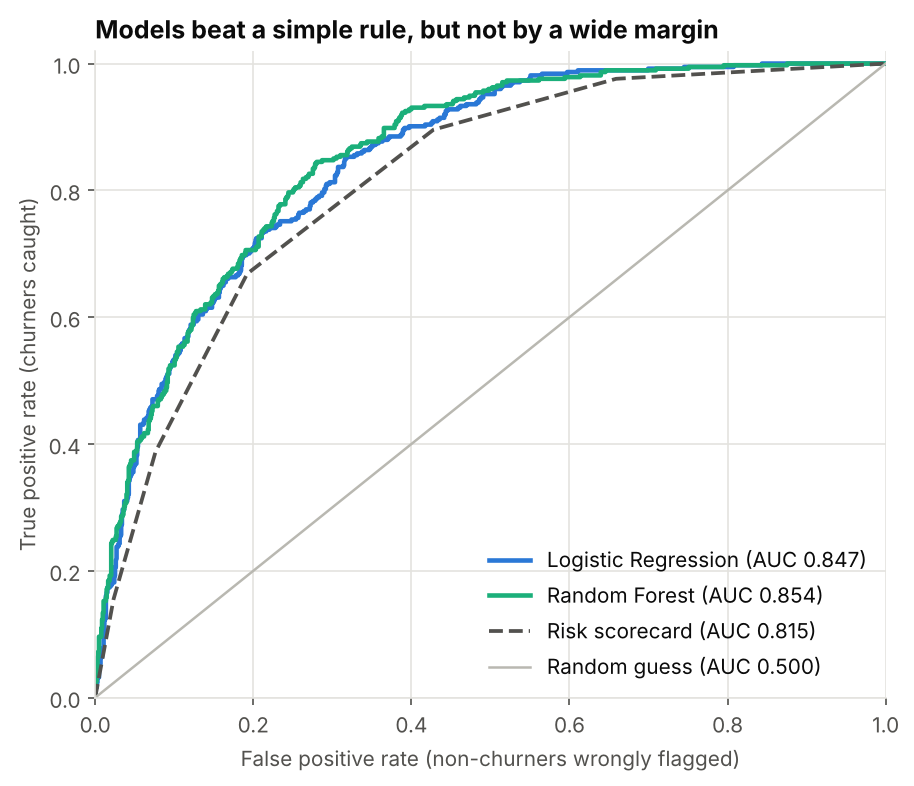

In [ ]:
fig, ax = plt.subplots(figsize=(6.8, 5.6))
curves = [('Logistic Regression', STAY, '-'), ('Random Forest', '#1baf7a', '-')]
for name, col, ls in curves:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax.plot(fpr, tpr, color=col, lw=2.2, ls=ls, label=f'{name} (AUC {roc_auc_score(y_test, probs[name]):.3f})')
fpr, tpr, _ = roc_curve(y_test, full.loc[X_test.index, 'risk_flag_count'])
ax.plot(fpr, tpr, color=INK2, lw=1.8, ls='--', label=f'Risk scorecard (AUC {scorecard_auc:.3f})')
ax.plot([0, 1], [0, 1], color=NEUTRAL, lw=1.2, label='Random guess (AUC 0.500)')
ax.set_xlabel('False positive rate (non-churners wrongly flagged)'); ax.set_ylabel('True positive rate (churners caught)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(color=GRID); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
ax.set_title('Models beat a simple rule, but not by a wide margin')
save(fig, 'model_roc_comparison.png')

**Observation (test set):**
- The always-"no churn" baseline has 73.5% accuracy and 0% recall, which shows why accuracy misleads.
- Logistic Regression: ROC-AUC 0.847, accuracy 80.2%, precision 64%, recall 57%, F1 0.60.
- Random Forest: ROC-AUC 0.854 (a difference of 0.007, well within the fold-to-fold noise of about 0.01).
- The simple five-flag scorecard reaches 0.815. The models add about 0.03 AUC over it.
- Test AUC (0.847) is close to the cross-validated AUC (about 0.858), so there is no sign of overfitting to the training set.

**Business meaning:** churn can be *ranked* well (AUC about 0.85), but not predicted with certainty: at a 0.5 cut-off the model misses 43% of churners. The extra value of ML over a transparent rule is real but modest.

### 8.7 Choosing a threshold: precision vs recall
A model outputs a *probability*. Flagging everyone above 0.5 is a default, not a business decision. A lower threshold catches more churners (higher recall) but contacts more customers who would have stayed (lower precision). The right balance depends on the **cost of an outreach offer vs the value of keeping a customer**.

In [ ]:
lr = fitted['Logistic Regression']; p_lr = probs['Logistic Regression']
rows = []
for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    pred = (p_lr >= t).astype(int)
    rows.append({'threshold': t, 'customers_flagged_pct': pred.mean() * 100,
                 'precision': precision_score(y_test, pred), 'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred)})
thr_table = pd.DataFrame(rows).set_index('threshold').round(2)
thr_table

**Observation:** moving the threshold from 0.5 to 0.30 raises recall from 57% to 75% (more churners caught) at the cost of precision falling from 64% to 54%, and the share of customers contacted rising from 23% to 37%. F1 barely moves (about 0.60 to 0.62), so F1 alone cannot choose the threshold. The business must.
We use **0.30** below as an *illustrative* operating point, not a recommendation.

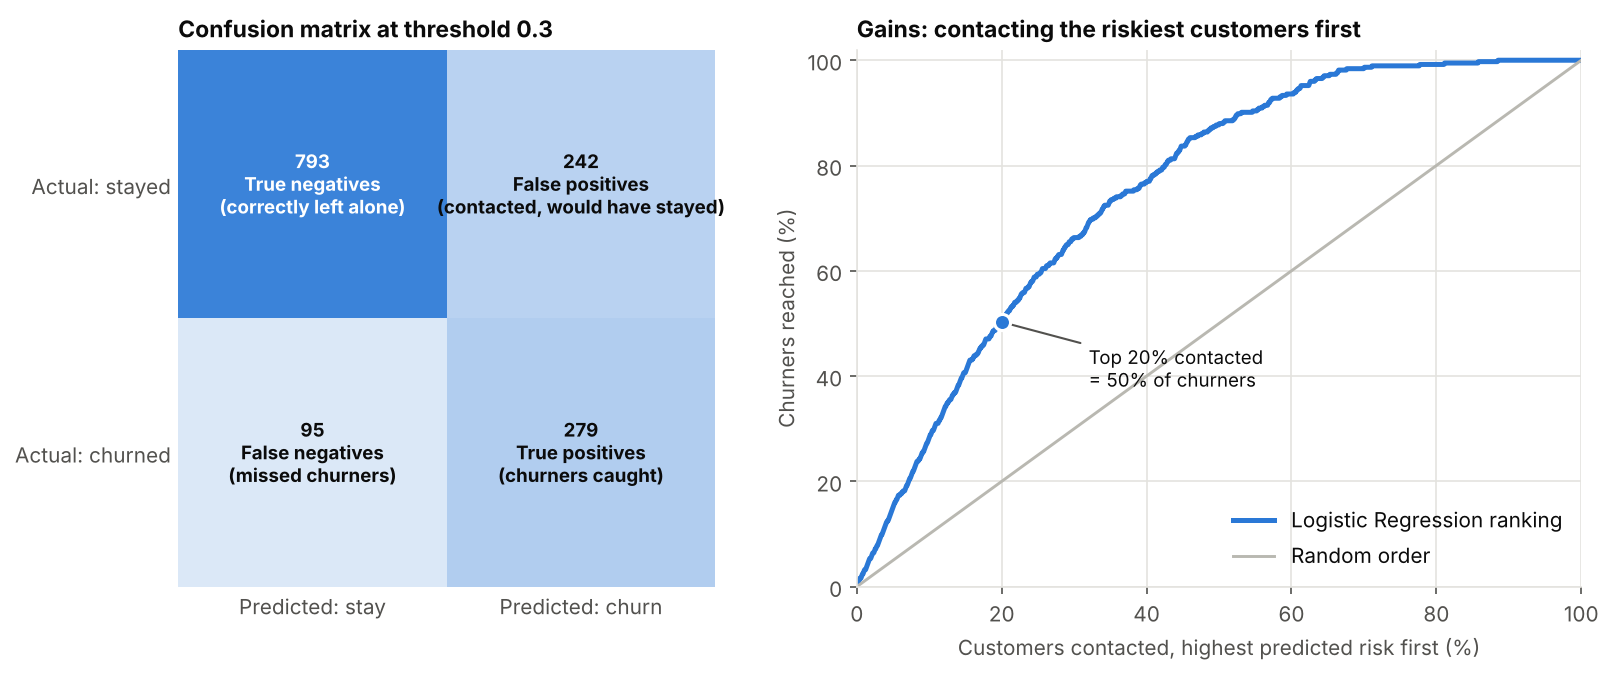

In [ ]:
THRESH = 0.30
pred = (p_lr >= THRESH).astype(int)
cm = confusion_matrix(y_test, pred)

# gains: sort customers by predicted risk, see how fast we collect real churners
order = np.argsort(-p_lr)
cum_churn = np.cumsum(y_test.values[order]) / y_test.sum()
contacted = np.arange(1, len(order) + 1) / len(order)
top20 = int(0.2 * len(order))
print(f'Contacting the top 20% by predicted risk reaches {cum_churn[top20 - 1]:.0%} of churners '
      f'(precision {y_test.values[order][:top20].mean():.0%} vs {y_test.mean():.0%} base rate)')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={'width_ratios': [1, 1.25]})
a1.imshow(cm, cmap=mpl.colors.LinearSegmentedColormap.from_list('b', ['#f1f6fc', STAY]), vmin=0, vmax=cm.max() * 1.1)
labels = [['True negatives\n(correctly left alone)', 'False positives\n(contacted, would have stayed)'],
          ['False negatives\n(missed churners)', 'True positives\n(churners caught)']]
for i in range(2):
    for j in range(2):
        a1.text(j, i, f'{cm[i, j]:,}\n{labels[i][j]}', ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > cm.max() * 0.55 else INK, fontweight='bold')
a1.set_xticks([0, 1], ['Predicted: stay', 'Predicted: churn']); a1.set_yticks([0, 1], ['Actual: stayed', 'Actual: churned'])
a1.tick_params(length=0); a1.spines[:].set_visible(False)
a1.set_title(f'Confusion matrix at threshold {THRESH}', fontsize=11)
a2.plot(contacted * 100, cum_churn * 100, color=STAY, lw=2.4, label='Logistic Regression ranking')
a2.plot([0, 100], [0, 100], color=NEUTRAL, lw=1.4, label='Random order')
a2.scatter([20], [cum_churn[top20 - 1] * 100], color=STAY, s=60, zorder=5, edgecolor='white', linewidth=1.5)
a2.annotate(f'Top 20% contacted\n= {cum_churn[top20 - 1]:.0%} of churners', (20, cum_churn[top20 - 1] * 100),
            xytext=(32, 38), fontsize=9, arrowprops=dict(arrowstyle='-', color=INK2))
a2.set_xlabel('Customers contacted, highest predicted risk first (%)'); a2.set_ylabel('Churners reached (%)')
a2.set_xlim(0, 100); a2.set_ylim(0, 102); a2.grid(color=GRID); a2.set_axisbelow(True); a2.legend(frameon=False, loc='lower right')
a2.set_title('Gains: contacting the riskiest customers first', fontsize=11)
fig.tight_layout()
save(fig, 'model_confusion_and_gains.png')

**Observation:** at 0.30 the model catches 279 of 374 churners in the test set, misses 95, and wrongly flags 242 customers who would have stayed. Contacting just the top 20% by predicted risk reaches about half of all churners (precision 67%, against a 27% base rate).
**Business meaning:** the ranking concentrates risk well. A team with capacity to contact 1 in 5 customers would reach about 2.5 times more churners than contacting at random.

### 8.8 Can we trust the probabilities? A calibration check
If the model says 30%, do about 30% of those customers churn? We sort test customers into 10 risk deciles and compare average predicted vs actual churn.

In [ ]:
cal = pd.DataFrame({'predicted': p_lr, 'actual': y_test.values})
cal['risk_decile'] = pd.qcut(cal.predicted.rank(method='first'), 10, labels=range(1, 11))
(cal.groupby('risk_decile', observed=True).agg(customers=('actual', 'size'),
                                              avg_predicted_pct=('predicted', lambda s: s.mean() * 100),
                                              actual_churn_pct=('actual', lambda s: s.mean() * 100)).round(1))

**Observation:** predicted and actual rates track each other closely across all ten deciles (lowest decile: 0.6% predicted vs 0% actual; top decile: 75.4% predicted vs 75.2% actual). Mid-range deciles show some noise (about 140 customers each).
**Business meaning:** the probabilities are reasonably well calibrated, so they can be used to size expected losses, not just to rank. Note that class-weighted ("balanced") models would *not* be calibrated this way, which is another reason to prefer the unweighted model here.

### 8.9 What does the model rely on? (Logistic Regression odds ratios)
An **odds ratio** above 1 means higher odds of churn when that feature is present, *holding the other features constant*; below 1 means lower odds. Numeric features are standardised, so tenure's value is "per +1 standard deviation (about 24 months)".
**Reading carefully:** these are *conditional* associations and can differ from the simple Phase 5 rates, and correlated features (internet type and add-ons) share credit, so individual coefficients are not stable causal effects.

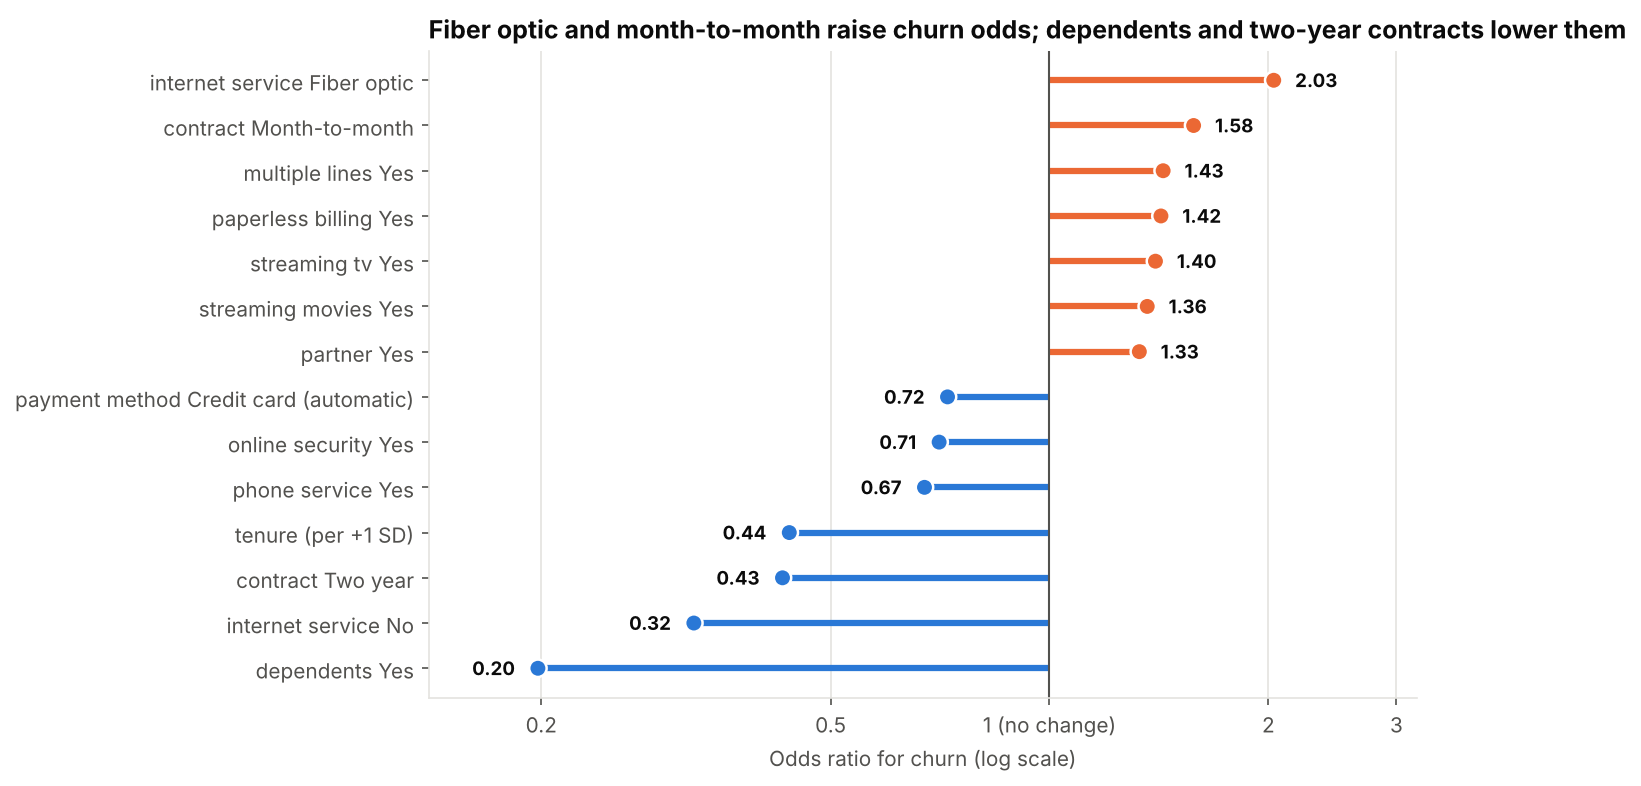

In [ ]:
pre = lr.named_steps['prep']; model = lr.named_steps['model']
names = [n.replace('cat__', '').replace('num__', '') for n in pre.get_feature_names_out()]
names = [n.replace('tenure_months', 'tenure (per +1 SD)').replace('monthly_charges', 'monthly charges (per +1 SD)').replace('_', ' ') for n in names]
orr = pd.Series(np.exp(model.coef_[0]), index=names).sort_values()
sel = pd.concat([orr.head(7), orr.tail(7)])
fig, ax = plt.subplots(figsize=(8.5, 5.6))
cols = [STAY if v < 1 else CHURN for v in sel.values]
ax.hlines(range(len(sel)), 1, sel.values, color=cols, lw=3)
ax.scatter(sel.values, range(len(sel)), color=cols, s=70, zorder=3, edgecolor='white', linewidth=1.2)
for i, v in enumerate(sel.values):
    ax.text(v * (1.07 if v >= 1 else 0.93), i, f'{v:.2f}', va='center', ha='left' if v >= 1 else 'right', fontsize=9, fontweight='bold')
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale('log'); ax.xaxis.set_minor_locator(mpl.ticker.NullLocator()); ax.set_xticks([0.2, 0.5, 1, 2, 3], ['0.2', '0.5', '1 (no change)', '2', '3'])
ax.set_yticks(range(len(sel)), sel.index); ax.set_xlim(0.14, 3.2)
ax.set_xlabel('Odds ratio for churn (log scale)'); ax.grid(axis='x', color=GRID); ax.set_axisbelow(True)
ax.set_title('Fiber optic and month-to-month raise churn odds; dependents and two-year contracts lower them')
ax.title.set_fontsize(11)
save(fig, 'model_logistic_odds_ratios.png')

**Observation:** the strongest risk-raising features are fiber optic internet (odds ratio about 2.0), month-to-month contract (1.6) and paperless billing, multiple lines and streaming (about 1.4). The strongest protective ones are having dependents (0.20), no internet service (0.32), a two-year contract (0.43) and longer tenure (0.44 per SD).
**Business meaning:** the model agrees with the EDA on the main story (contract, fiber, tenure, dependents). Two things differ from the simple rates and deserve scepticism: streaming and multiple lines look *harmful* here only after adjusting for everything else (in the Phase 5 raw rates they were neutral or slightly protective), which is typical of correlated features. Use these for hypothesis-building, not as effect sizes.

### 8.10 Is it good enough to act on? An illustrative break-even
A retention offer is worth sending when: **P(churn) x P(offer works) x value kept > cost of offer**.

> **ILLUSTRATIVE ONLY.** The offer cost, success rate and months of value below are *assumptions invented for this demo*, not facts from the data. A real project would take them from the company. The point is the logic and how sensitive the answer is.

In [ ]:
OFFER_COST = 30          # assumed cost per retention offer ($)
MONTHS_KEPT = 12         # assumed months of revenue kept if the offer works
test_ctx = full.loc[X_test.index, ['monthly_charges']].assign(p=p_lr, churned=y_test.values)

rows = []
for success in [0.10, 0.20, 0.30]:
    ev = test_ctx.p * success * test_ctx.monthly_charges * MONTHS_KEPT - OFFER_COST
    contact = ev > 0
    realised = (contact & (test_ctx.churned == 1)).sum() * success * test_ctx.monthly_charges[contact & (test_ctx.churned == 1)].mean() * MONTHS_KEPT \
               - contact.sum() * OFFER_COST
    rows.append({'assumed_success_rate': success, 'customers_worth_contacting': int(contact.sum()),
                 'pct_of_test_customers': contact.mean() * 100, 'est_net_value_$': realised})
pd.DataFrame(rows).set_index('assumed_success_rate').round(0)

**Observation (under the invented assumptions only):** on the 1,409 test customers, a positive-expected-value rule would contact about 31% of customers at a 10% offer success rate, 46% at 20% and 52% at 30%. The estimated net value rises from about $11K to $38K to $69K across those three cases.
**Business meaning:** the answer is highly sensitive to a number the data cannot supply, the offer success rate. A 3x change in it moves the estimated value about 6.5x. So the model supports *running a pilot* to measure the success rate; it does not prove a profit. Treat these dollar figures as an illustration of the method, not a result.

### 8.11 Conclusion and limitations
**Can churn risk be predicted reliably enough to support action?** Partly yes:
- **Ranking is good** (AUC about 0.85; top 20% of customers hold about half of churners) and the probabilities are reasonably calibrated.
- **Individual certainty is not available**: at practical thresholds roughly half of flagged customers would have stayed anyway.
- **The advantage over a simple, explainable scorecard is modest** (AUC 0.85 vs 0.82). For a first retention pilot, the scorecard or the logistic model is enough; the random forest adds complexity without meaningful gain.

**Limitations (be ready to state these):**
- Single snapshot, no dates: we cannot test whether the model holds up on *future* customers (the real test), only on a random hold-out.
- Synthetic, California-only data.
- Models are untuned; no cost-sensitive optimisation; one random split (cross-validation helps, but an interval on test metrics would be better).
- Predicting who churns is not the same as knowing whom a retention offer will *save*. That needs an experiment (uplift thinking), not a classifier.
- Correlated features make individual coefficients unreliable.

---
# Phase 9: Power BI preparation
The dashboard itself is built in Power BI Desktop (see `powerbi/POWERBI_GUIDE.md`). It reads `data/clean/customer_churn_clean.csv` directly. One page (Churn Drivers) needs a statistic that is awkward to compute in DAX, Cramér's V from Phase 6, so we export it as a small lookup table.

**Important:** this table is a *Python result copied into Power BI*. It does not recalculate when slicers change. Label it as such on the page.

In [ ]:
drivers = chi.copy()
drivers['driver'] = drivers.variable.str.replace(r' \(.*\)', '', regex=True).str.replace('_', ' ').str.title()
drivers['population'] = np.where(drivers.variable.str.contains('internet customers'), 'Internet customers only',
                         np.where(drivers.variable.str.contains('phone customers'), 'Phone customers only', 'All customers'))
drivers = (drivers.rename(columns={'n': 'customers_tested', 'p': 'p_value', 'effect': 'effect_size',
                                   'significant_bonferroni': 'significant_after_correction'})
                  .sort_values('cramers_v', ascending=False).reset_index(drop=True))
drivers['rank'] = drivers.index + 1
cols = ['rank', 'driver', 'population', 'customers_tested', 'cramers_v', 'effect_size', 'p_value', 'significant_after_correction']
drivers[cols].round({'cramers_v': 3, 'p_value': 4}).to_csv('../powerbi/churn_driver_effects.csv', index=False)
pd.read_csv('../powerbi/churn_driver_effects.csv').head(8)